# Inter-annotator agreement: OpenAI models, open models, and human annotators

**Questions:** how well do two annotators agree when they label the same web pages
with one topic and one format label each, and which model agrees best with a human
annotator?

**Data:** the first 100 parallel Nemotron-CC documents (the human-evaluation sample,
`data/human_evaluation/manifest.json`), each in six languages.

- **OpenAI models:** two models labelled all 100 documents in all six languages with
  `generate_openai_labels.py` (launcher: `hpc/roihu/run_openai_labels.sh`). They got
  exactly the prompts of the open-model runs and returned one hard label per document,
  so there are 600 label pairs per label type.
- **Human annotator:** 50 of the English documents (items 1–50 of the English sheet),
  labelled for topic and for format in Label Studio and exported to
  `data/human_evaluation/<label type>-annotations-<language>.csv`. More languages or
  annotators are picked up automatically when their files are added.
- **Open models:** the label distribution runs in `results/distribution` (five chat
  models and the Clef decision model), reduced to their most probable label where a
  single label is needed. Section 4 compares every model with the human annotator;
  section 10 compares one open model (Qwen3.8-27B) with one OpenAI model in all six
  languages; section 11 compares two open models (Clef and Qwen3.8-27B) on all 2,000
  documents they labelled in six languages, using their full label distributions.

**Measures:**

| Measure | What it tells you |
|---|---|
| Agreement | Share of items where both annotators chose the same label |
| Cohen's κ | Agreement corrected for the agreement expected by chance, given how often each annotator uses each label. 0 is chance, 1 is perfect; above 0.8 is usually called almost perfect, 0.6–0.8 substantial (Landis & Koch) |
| Macro F1 | F1 per label, averaged with every label counting equally, so rare labels weigh as much as common ones. It is the same whichever annotator is taken as the reference |
| Weighted F1 | F1 per label, weighted by how often the *first* annotator of the pair used the label, so common labels dominate |

Labels that neither annotator ever used are left out of the F1 averages.

**Sections:** 1 loads and checks the labels · 2 defines the measures · 3 overall
agreement with confidence intervals · 4 agreement of every model with the human
annotator · 5 agreement per language · 6 agreement per label and label usage · 7 which
labels get confused · 8 consistency across languages · 9 example disagreements ·
10 an open model against an OpenAI model · 11 a candidate open model against the chosen
one (Clef against Qwen3.8-27B) · 12 summary. Sections 5–9 look at one pair of annotators
in detail (`FOCUS_PAIR`).

**Running it:** on Roihu, `module load python-vllm/0.19.1` provides pandas, matplotlib
and JupyterLab; locally, use the `mwo-local` venv. The notebook only reads files and
runs in a few minutes on a network mount (most of it reading the open models' result
files for section 11) and faster on Roihu itself.

## Setup

Imports and the repository root. Cohen's κ and F1 are checked against the project's
own implementations in `scripts/data_analysis/distribution_metrics.py`
(`cohen_kappa`, `f1_scores`), so the numbers here match the evaluation scripts.

In [1]:
from __future__ import annotations

import csv
import json
import math
import re
import statistics
import sys
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.colors import LinearSegmentedColormap

# Find the repository root whether Jupyter runs from the root or from notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "data_analysis"))

from distribution_metrics import (  # the project's reference implementations
    cohen_kappa,
    entropy_bits,                 # entropy of one distribution, in bits
    expected_calibration_error,   # confidence vs. how often the model was right
    f1_scores,
    jensen_shannon_bits,          # divergence between two distributions, 0-1 bit
    random_pair_jsd_bits,         # divergence between unrelated documents (baseline)
    read_distribution_file,       # loads and validates one result file
    top_index,                    # index of the most probable label
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 400)

## Parameters

- `API_MODELS`: display name → directory name under `API_DIR`
  (`<API_DIR>/<model>/<label type>/<language>-parallel.jsonl`).
- `HUMAN_ANNOTATORS`: display name → directory with that annotator's files. Add one
  entry per annotator.
- `HUMAN_SOURCES`: the file layouts tried for each label type and language, as
  (file name pattern, column holding the label). The first is a Label Studio export,
  where the chosen label is in the `sentiment` column (Label Studio's default name for
  a choice field) and the label type is only in the file name. The second is the
  original sheet from `create_human_eval_sample.py`, filled in by hand. The first file
  that exists and has labels is used.
- `OPEN_MODELS`: display name → model name in `DISTRIBUTION_DIR`
  (`<model>-annotations/<label type>/<language>-parallel.jsonl`), for section 4. Their
  hard label is the most probable label of each distribution.
- `REFERENCE_ANNOTATOR`: the human annotator every model is compared with in section 4.
- `OPEN_FOCUS_PAIR`: (open model, OpenAI model) compared in section 10. The open model
  is loaded in all languages, with its label probabilities.
- `CANDIDATE_PAIR`: (candidate model, chosen model) compared in section 11 on all their
  documents. Both must be in `OPEN_MODELS`.
- `CONSENSUS_VOTERS`: the reference models of section 11. They should come from other
  model families than the pair, so neither model of the pair is favoured by a relative.
- `LOGS_DIR`, `BU_PER_GPU_HOUR`: job logs and the CSC billing rate, for the speed
  comparison in section 11.
- `FOCUS_PAIR`: the two annotators examined in detail in sections 5–9. Section 3
  covers every pair. For weighted F1 the first one is the reference. Set it to e.g.
  `("Human", "GPT-6.1 Sol")` to study one model's disagreements with the human.
- `LANGUAGES`, `LABEL_TYPES`, `LABEL_FILES`: what to compare and the label definitions.
- `BOOTSTRAP_SAMPLES`, `SEED`: settings of the confidence intervals in sections 3 and 4.
- `EXAMPLES_SHOWN`, `SNIPPET_CHARS`: size of the example tables in sections 4 and 9.

In [2]:
API_DIR = ROOT / "results/api"
API_MODELS = {
    "GPT-6 Luna": "gpt-6-luna",
    "GPT-6.1 Sol": "gpt-6.1-sol",
}
HUMAN_ANNOTATORS = {
    "Human": ROOT / "data/human_evaluation",
}
HUMAN_SOURCES = (
    ("{label_type}-annotations-{language}.csv", "sentiment"),   # Label Studio export
    ("{language}.csv", "{label_type}_label"),                    # sheet filled in by hand
)
DISTRIBUTION_DIR = ROOT / "results/distribution"
OPEN_MODELS = {
    "Llama-3.1-8B": "Llama-3.1-8B-Instruct",
    "Qwen3.8-27B": "Qwen3.8-27B",
    "Gemma-4-31B": "gemma-4-31B-it",
    "Qwen3.5-122B-A10B": "Qwen3.5-122B-A10B",
    "Mistral-Medium-3.5-128B": "Mistral-Medium-3.5-128B",
    "Clef": "clef",
}
REFERENCE_ANNOTATOR = "Human"
OPEN_FOCUS_PAIR = ("Qwen3.8-27B", "GPT-6.1 Sol")
CANDIDATE_PAIR = ("Clef", "Qwen3.8-27B")
CONSENSUS_VOTERS = ("Gemma-4-31B", "Mistral-Medium-3.5-128B")
LOGS_DIR = ROOT / "logs"
BU_PER_GPU_HOUR = 200
FOCUS_PAIR = ("GPT-6 Luna", "GPT-6.1 Sol")

LABEL_TYPES = ("topic", "format")
LANGUAGES = ("english", "finnish", "german", "hungarian", "icelandic", "ukrainian")
LABEL_FILES = {
    "topic": ROOT / "scripts/data_processing/topics.yaml",
    "format": ROOT / "scripts/data_processing/formats.yaml",
}
BOOTSTRAP_SAMPLES = 2000
SEED = 0
EXAMPLES_SHOWN = 8
SNIPPET_CHARS = 300

# One fixed colour per annotator, in this order, so an annotator keeps its colour in
# every plot. The first three are distinguishable with colour-vision deficiencies.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
# The two models of section 11; different hues from the annotators above, and
# different marker shapes in the plot, so they are not told apart by colour alone.
PAIR_COLORS = dict(zip(CANDIDATE_PAIR, ["#4a3aa7", "#008300"]))
# Single-hue ramp for counts (light = few, dark = many).
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "font.size": 10,
})

## 1. Load the labels and check the data

**Label names.** The model results store each label's *short name* (e.g.
`Science & Tech.`); the human annotations use the *full name* (e.g.
`Science, Math & Technology`). Everything is converted to short names here. A label
that is in neither list stops the notebook, because a misspelt label would otherwise
count as a disagreement.

**Checks on the human files.** Each document may be labelled once, by one annotator
per file, and its text must be identical to the text the models labelled; anything
else stops the notebook.

**Open models.** Only the documents of the evaluation sample are read. Most open
models are needed for section 4 alone, so only the languages a human labelled are
read; the open model of `OPEN_FOCUS_PAIR` is read in every language, and its label
probabilities are kept in `probabilities[(label_type, language)]` for section 10.

**Result.** `annotations[(annotator, label_type, language)]` maps document IDs to
short label names, and `explanations` holds the one-line explanations (where the
annotator gave one) for the example tables. `texts[language]` holds the document
texts. `annotators` lists the annotators of sections 3 and 5–10 (OpenAI models and
humans); `compared_models` lists every model compared with the human in section 4.

In [3]:
label_names: dict[str, list[str]] = {}       # label type -> short names in label-file order
to_short: dict[str, dict[str, str]] = {}     # label type -> {full or short name: short name}
for label_type, path in LABEL_FILES.items():
    definitions = yaml.safe_load(path.read_text(encoding="utf-8"))
    label_names[label_type] = [str(item["short_name"]) for item in definitions]
    to_short[label_type] = {str(item["name"]): str(item["short_name"]) for item in definitions}
    to_short[label_type].update({name: name for name in label_names[label_type]})

annotations: dict[tuple[str, str, str], dict[str, str]] = {}
explanations: dict[tuple[str, str, str], dict[str, str]] = {}
texts: dict[str, dict[str, str]] = {}
notes: list[str] = []


def read_api_file(path: Path, label_type: str) -> tuple[dict[str, str], dict[str, str], dict[str, str]]:
    # Return labels, explanations and texts by document ID, validating every record.
    labels, reasons, documents = {}, {}, {}
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            doc_id, label = record["id"], record["label"]
            if doc_id in labels:
                raise ValueError(f"{path}:{line_number}: duplicate document {doc_id}")
            if label not in label_names[label_type]:
                raise ValueError(f"{path}:{line_number}: unknown {label_type} label {label!r}")
            labels[doc_id], reasons[doc_id], documents[doc_id] = label, record.get("explanation", ""), record["text"]
    return labels, reasons, documents


for annotator, directory in API_MODELS.items():
    for label_type in LABEL_TYPES:
        for language in LANGUAGES:
            path = API_DIR / directory / label_type / f"{language}-parallel.jsonl"
            if not path.exists():
                notes.append(f"{annotator}: no {label_type} file for {language} ({path.relative_to(ROOT)})")
                continue
            labels, reasons, documents = read_api_file(path, label_type)
            annotations[(annotator, label_type, language)] = labels
            explanations[(annotator, label_type, language)] = reasons
            texts.setdefault(language, {}).update(documents)

manifest = json.loads((ROOT / "data/human_evaluation/manifest.json").read_text(encoding="utf-8"))
sample_ids = set(manifest["sampled_ids"])


def read_human_file(path: Path, column: str, label_type: str, language: str) -> tuple[dict[str, str], dict[str, str]]:
    # Return labels (short names) and explanations by document ID from one annotation file.
    with path.open(encoding="utf-8-sig", newline="") as handle:
        rows = list(csv.DictReader(handle))
    if not rows or column not in rows[0] or "doc_id" not in rows[0]:
        raise ValueError(f"{path}: expected columns 'doc_id' and {column!r}")
    rows = [row for row in rows if row[column].strip()]
    if not rows:
        return {}, {}
    if len({row.get("annotator", "") for row in rows}) > 1:
        raise ValueError(f"{path}: labels from several annotators; export one file per annotator")
    repeated = [doc_id for doc_id, n in Counter(row["doc_id"] for row in rows).items() if n > 1]
    if repeated:
        raise ValueError(f"{path}: documents labelled more than once: {repeated[:5]}")
    unknown = sorted({row[column].strip() for row in rows} - set(to_short[label_type]))
    if unknown:
        raise ValueError(f"{path}: unknown {label_type} labels {unknown} (see {label_type}_labels.csv)")
    for row in rows:
        expected = texts.get(language, {}).get(row["doc_id"])
        if "text" in row and expected is not None and row["text"] != expected:
            raise ValueError(f"{path}: the text of document {row['doc_id']} differs from the text the models labelled")
    labels = {row["doc_id"]: to_short[label_type][row[column].strip()] for row in rows}
    reasons = {row["doc_id"]: row.get(f"{label_type}_explanation", "") for row in rows}
    return labels, reasons


for annotator, directory in HUMAN_ANNOTATORS.items():
    for language in LANGUAGES:
        for label_type in LABEL_TYPES:
            for pattern, column in HUMAN_SOURCES:
                path = directory / pattern.format(label_type=label_type, language=language)
                if not path.exists():
                    continue
                labels, reasons = read_human_file(path, column.format(label_type=label_type), label_type, language)
                if not labels:
                    notes.append(f"{annotator}: {path.name} has no {label_type} labels; skipped")
                    continue
                annotations[(annotator, label_type, language)] = labels
                explanations[(annotator, label_type, language)] = reasons
                notes.append(f"{annotator}: {len(labels)} {label_type} labels for {language} from {path.name}")
                break

annotators = [name for name in (*API_MODELS, *HUMAN_ANNOTATORS) if any(key[0] == name for key in annotations)]
COLORS = dict(zip(annotators, PALETTE))
assert len(annotators) <= len(PALETTE), "add colours to PALETTE for more annotators"
for name in FOCUS_PAIR:
    assert name in annotators, f"FOCUS_PAIR annotator {name!r} has no labels"

# Open models: the top label of each distribution, for the languages a human labelled
# (every language for the open model of OPEN_FOCUS_PAIR).
human_languages = sorted({language for (name, _, language) in annotations if name in HUMAN_ANNOTATORS})
probabilities: dict[tuple[str, str], dict[str, dict[str, float]]] = {}
for model, directory in OPEN_MODELS.items():
    for label_type in LABEL_TYPES:
        for language in (LANGUAGES if model == OPEN_FOCUS_PAIR[0] else human_languages):
            path = DISTRIBUTION_DIR / f"{directory}-annotations" / label_type / f"{language}-parallel.jsonl"
            if not path.exists():
                notes.append(f"{model}: no {label_type} run for {language} ({path.relative_to(ROOT)})")
                continue
            labels = {}
            with path.open(encoding="utf-8") as handle:
                for line in handle:
                    record = json.loads(line)
                    if record["id"] not in sample_ids:
                        continue
                    if record["label"] not in label_names[label_type]:
                        raise ValueError(f"{path}: unknown {label_type} label {record['label']!r}")
                    if record["text"] != texts[language].get(record["id"], record["text"]):
                        raise ValueError(f"{path}: the text of document {record['id']} differs from the OpenAI runs")
                    labels[record["id"]] = record["label"]
                    if model == OPEN_FOCUS_PAIR[0]:
                        probabilities.setdefault((label_type, language), {})[record["id"]] = record["label_probs"]
            if sample_ids - labels.keys():
                notes.append(f"{model}: {len(sample_ids - labels.keys())} sample documents missing from {path.relative_to(ROOT)}")
            annotations[(model, label_type, language)] = labels
compared_models = [name for name in (*API_MODELS, *OPEN_MODELS) if any(key[0] == name for key in annotations)]

inventory = pd.DataFrame(
    [
        {"annotator": a, "label type": t, **{lang: len(annotations.get((a, t, lang), {})) or "-" for lang in LANGUAGES}}
        for a in (*annotators, *(m for m in compared_models if m not in annotators)) for t in LABEL_TYPES
    ]
)
display(inventory)
for note in notes:
    print("NOTE:", note)

,annotator,label type,english,finnish,german,hungarian,icelandic,ukrainian
0,GPT-6 Luna,topic,100,100,100,100,100,100
1,GPT-6 Luna,format,100,100,100,100,100,100
2,GPT-6.1 Sol,topic,100,100,100,100,100,100
3,GPT-6.1 Sol,format,100,100,100,100,100,100
4,Human,topic,50,-,-,-,-,-
5,Human,format,50,-,-,-,-,-
6,Llama-3.1-8B,topic,100,-,-,-,-,-
7,Llama-3.1-8B,format,100,-,-,-,-,-
8,Qwen3.8-27B,topic,100,100,100,100,100,100
9,Qwen3.8-27B,format,100,100,100,100,100,100


NOTE: Human: 50 topic labels for english from topic-annotations-english.csv
NOTE: Human: 50 format labels for english from format-annotations-english.csv
NOTE: Human: finnish.csv has no topic labels; skipped
NOTE: Human: finnish.csv has no format labels; skipped


### Do the annotators cover the same documents?

Agreement is only defined on items both annotators labelled. `shared_items` returns
those items for a pair of annotators: the (language, document) keys present for both.
The check below also confirms that the documents are the human-evaluation sample.

In [4]:
def shared_items(first: str, second: str, label_type: str, languages=LANGUAGES) -> list[tuple[str, str, str, str]]:
    # Return (language, document ID, first annotator's label, second annotator's label) for shared items.
    items = []
    for language in languages:
        a, b = annotations.get((first, label_type, language)), annotations.get((second, label_type, language))
        if a is None or b is None:
            continue
        items += [(language, doc_id, a[doc_id], b[doc_id]) for doc_id in sorted(a.keys() & b.keys())]
    return items


coverage = []
for first, second in combinations(annotators, 2):
    for label_type in LABEL_TYPES:
        items = shared_items(first, second, label_type)
        documents = {doc_id for _, doc_id, _, _ in items}
        coverage.append({
            "pair": f"{first} vs {second}", "label type": label_type, "shared items": len(items),
            "documents": len(documents), "languages": len({language for language, *_ in items}),
            "all in the human-evaluation sample": documents <= sample_ids,
        })
display(pd.DataFrame(coverage))

,pair,label type,shared items,documents,languages,all in the human-evaluation sample
0,GPT-6 Luna vs GPT-6.1 Sol,topic,600,100,6,True
1,GPT-6 Luna vs GPT-6.1 Sol,format,600,100,6,True
2,GPT-6 Luna vs Human,topic,50,50,1,True
3,GPT-6 Luna vs Human,format,50,50,1,True
4,GPT-6.1 Sol vs Human,topic,50,50,1,True
5,GPT-6.1 Sol vs Human,format,50,50,1,True


## 2. The measures

All four measures are computed from a **confusion matrix**: `matrix[i, j]` counts the
items the first annotator gave label `i` and the second label `j`. The diagonal holds
the agreements.

- Agreement: the diagonal's share of all items.
- Cohen's κ: `(observed − expected) / (1 − expected)`, where `expected` is the
  agreement two annotators would reach by chance if each kept their own label
  frequencies.
- F1 of a label: `2·both / (first's count + second's count)`. Macro F1 averages it
  over the labels used by at least one of the two; weighted F1 weights it by the first
  annotator's count.

Working from the matrix makes the bootstrap in sections 3 and 4 fast. The last lines verify
that the functions give the same κ and macro F1 as the project's reference
implementations.

In [5]:
def confusion_matrix(pairs: list[tuple[str, str]], label_type: str) -> np.ndarray:
    # Count label pairs: rows are the first annotator's label, columns the second's.
    index = {name: position for position, name in enumerate(label_names[label_type])}
    matrix = np.zeros((len(index), len(index)), dtype=np.int64)
    for first_label, second_label in pairs:
        matrix[index[first_label], index[second_label]] += 1
    return matrix


def agreement_scores(matrix: np.ndarray) -> dict[str, float]:
    # Return agreement, Cohen's kappa, macro F1 and weighted F1 from a confusion matrix.
    total = matrix.sum()
    if total == 0:
        raise ValueError("No items to compare")
    both = np.diag(matrix).astype(float)
    first, second = matrix.sum(axis=1).astype(float), matrix.sum(axis=0).astype(float)
    observed = both.sum() / total
    expected = (first * second).sum() / total**2
    used = (first + second) > 0                      # labels at least one annotator used
    f1 = np.zeros(len(both))
    f1[used] = 2 * both[used] / (first[used] + second[used])
    return {
        "agreement": observed,
        "kappa": (observed - expected) / (1 - expected) if expected < 1 else 1.0,
        "macro F1": f1[used].mean(),
        "weighted F1": (f1 * first).sum() / first.sum(),
    }


# Check against the project's implementations on the focus pair.
for label_type in LABEL_TYPES:
    items = shared_items(*FOCUS_PAIR, label_type)
    scores = agreement_scores(confusion_matrix([(a, b) for *_, a, b in items], label_type))
    index = {name: position for position, name in enumerate(label_names[label_type])}
    index_pairs = [(index[a], index[b]) for *_, a, b in items]
    reference_macro_f1, _ = f1_scores(index_pairs, label_names[label_type])
    assert abs(scores["kappa"] - cohen_kappa(index_pairs, len(index))) < 1e-12
    assert abs(scores["macro F1"] - reference_macro_f1) < 1e-12
print("kappa and macro F1 match scripts/data_analysis/distribution_metrics.py")

kappa and macro F1 match scripts/data_analysis/distribution_metrics.py


## 3. Overall agreement

One row per annotator pair and label type, over all the items the pair shares. Note
that pairs involving the human annotator cover far fewer items than the pair of OpenAI
models (see the `items` column), so rows of this table are not directly comparable;
section 4 compares all models with the human on the same items.

**Confidence intervals.** The six language versions of a document are not independent:
if two annotators disagree on a page in English, they often disagree on its
translations too. Treating the 600 items as independent would make the intervals too
narrow. The bootstrap therefore resamples *documents*: each of `BOOTSTRAP_SAMPLES`
rounds draws as many documents as there are, with replacement, and takes all language
versions of each drawn document. The interval is the 2.5th to 97.5th percentile of the
scores over the rounds.

In [6]:
def bootstrap_intervals(items: list[tuple[str, str, str, str]], label_type: str) -> dict[str, tuple[float, float]]:
    # Return 95% intervals of the agreement scores, resampling documents.
    documents = sorted({doc_id for _, doc_id, _, _ in items})
    position = {doc_id: row for row, doc_id in enumerate(documents)}
    index = {name: column for column, name in enumerate(label_names[label_type])}
    # One confusion matrix per document; a resample is a weighted sum of them.
    per_document = np.zeros((len(documents), len(index), len(index)))
    for _, doc_id, first_label, second_label in items:
        per_document[position[doc_id], index[first_label], index[second_label]] += 1
    rng = np.random.default_rng(SEED)
    draws = rng.multinomial(len(documents), np.full(len(documents), 1 / len(documents)), size=BOOTSTRAP_SAMPLES)
    samples = [agreement_scores(np.tensordot(counts, per_document, axes=1)) for counts in draws]
    return {
        name: tuple(np.percentile([sample[name] for sample in samples], [2.5, 97.5]))
        for name in samples[0]
    }


overall_rows = []
for first, second in combinations(annotators, 2):
    for label_type in LABEL_TYPES:
        items = shared_items(first, second, label_type)
        if not items:
            continue
        scores = agreement_scores(confusion_matrix([(a, b) for *_, a, b in items], label_type))
        intervals = bootstrap_intervals(items, label_type)
        row = {"pair": f"{first} vs {second}", "label type": label_type, "items": len(items),
               "documents": len({doc_id for _, doc_id, _, _ in items})}
        for name, value in scores.items():
            row[name] = round(value, 3)
            row[f"{name} 95% CI"] = f"{intervals[name][0]:.3f}–{intervals[name][1]:.3f}"
        overall_rows.append(row)
overall = pd.DataFrame(overall_rows)
display(overall)

,pair,label type,items,documents,agreement,agreement 95% CI,kappa,kappa 95% CI,macro F1,macro F1 95% CI,weighted F1,weighted F1 95% CI
0,GPT-6 Luna vs GPT-6.1 Sol,topic,600,100,0.867,0.810–0.917,0.856,0.794–0.909,0.824,0.699–0.862,0.869,0.814–0.921
1,GPT-6 Luna vs GPT-6.1 Sol,format,600,100,0.795,0.742–0.845,0.782,0.724–0.835,0.734,0.626–0.790,0.790,0.734–0.844
2,GPT-6 Luna vs Human,topic,50,50,0.680,0.540–0.800,0.650,0.498–0.776,0.508,0.364–0.674,0.697,0.568–0.827
3,GPT-6 Luna vs Human,format,50,50,0.400,0.260–0.540,0.369,0.222–0.502,0.372,0.230–0.452,0.362,0.233–0.503
4,GPT-6.1 Sol vs Human,topic,50,50,0.740,0.620–0.860,0.717,0.574–0.842,0.588,0.435–0.750,0.729,0.605–0.858
5,GPT-6.1 Sol vs Human,format,50,50,0.440,0.300–0.580,0.412,0.265–0.551,0.384,0.246–0.483,0.413,0.277–0.560


## 4. Agreement with the human annotator

This is the comparison the human annotation was made for: **which model labels pages
most like a person does?** Every model (the OpenAI models and the open models' most
probable labels) is compared with the human annotator on exactly the same items, the
documents the human labelled, so the rows are directly comparable.

Weighted F1 here weights each label by how often the *human* used it. The intervals
are the document bootstrap of section 3.

**How to read it.**

- With 50 documents the intervals are wide (about ±0.1 for κ). Models whose intervals
  overlap heavily can't be ranked by this sample; look for models that are clearly
  below the rest.
- One annotator is not ground truth. On pages that fit two labels, a model that
  disagrees with the human may be making an equally defensible choice. A second
  annotator's agreement with the first would show how much agreement to expect at all.
- The last row per label type shows the two focus models' agreement *with each other*
  on the same items, as a reference point.

In [7]:
human_rows = []
if REFERENCE_ANNOTATOR not in annotators:
    print(f"No labels from {REFERENCE_ANNOTATOR!r} yet; section 4 is skipped.")
for label_type in LABEL_TYPES if REFERENCE_ANNOTATOR in annotators else ():
    comparisons = [(REFERENCE_ANNOTATOR, model) for model in compared_models]
    for reference, model in comparisons:
        items = shared_items(reference, model, label_type)
        if not items:
            continue
        scores = agreement_scores(confusion_matrix([(a, b) for *_, a, b in items], label_type))
        intervals = bootstrap_intervals(items, label_type)
        row = {"label type": label_type, "model": model, "items": len(items)}
        for name, value in scores.items():
            row[name] = round(value, 3)
            row[f"{name} 95% CI"] = f"{intervals[name][0]:.3f}–{intervals[name][1]:.3f}"
        row["kappa low"], row["kappa high"] = intervals["kappa"]
        human_rows.append(row)
human_agreement = pd.DataFrame(human_rows)

for label_type in LABEL_TYPES if human_rows else ():
    part = human_agreement[human_agreement["label type"] == label_type].sort_values("kappa", ascending=False)
    print(f"{label_type.upper()}: agreement with {REFERENCE_ANNOTATOR}")
    display(part.drop(columns=["label type", "kappa low", "kappa high"]).reset_index(drop=True))
    # The focus models with each other, on the items the human labelled.
    human_items = {(language, doc_id) for language, doc_id, *_ in shared_items(REFERENCE_ANNOTATOR, FOCUS_PAIR[0], label_type)}
    between = [item for item in shared_items(*FOCUS_PAIR, label_type) if (item[0], item[1]) in human_items]
    if between and REFERENCE_ANNOTATOR not in FOCUS_PAIR:
        scores = agreement_scores(confusion_matrix([(a, b) for *_, a, b in between], label_type))
        print(f"  for reference, {FOCUS_PAIR[0]} vs {FOCUS_PAIR[1]} on the same {len(between)} items: "
              f"agreement {scores['agreement']:.3f}, kappa {scores['kappa']:.3f}, macro F1 {scores['macro F1']:.3f}\n")

TOPIC: agreement with Human


,model,items,agreement,agreement 95% CI,kappa,kappa 95% CI,macro F1,macro F1 95% CI,weighted F1,weighted F1 95% CI
0,Qwen3.8-27B,50,0.76,0.640–0.860,0.738,0.598–0.846,0.705,0.548–0.823,0.741,0.598–0.853
1,GPT-6.1 Sol,50,0.74,0.620–0.860,0.717,0.574–0.842,0.588,0.435–0.750,0.751,0.604–0.861
2,Clef,50,0.70,0.580–0.820,0.673,0.535–0.799,0.515,0.379–0.680,0.696,0.548–0.817
3,Qwen3.5-122B-A10B,50,0.70,0.560–0.820,0.672,0.525–0.800,0.579,0.441–0.752,0.686,0.545–0.807
4,Mistral-Medium-3.5-128B,50,0.68,0.540–0.800,0.652,0.504–0.778,0.507,0.397–0.686,0.669,0.521–0.792
5,GPT-6 Luna,50,0.68,0.540–0.800,0.650,0.498–0.776,0.508,0.364–0.674,0.663,0.505–0.791
6,Gemma-4-31B,50,0.66,0.520–0.780,0.629,0.475–0.757,0.509,0.360–0.686,0.652,0.500–0.773
7,Llama-3.1-8B,50,0.52,0.380–0.660,0.479,0.331–0.625,0.326,0.227–0.459,0.494,0.350–0.649


  for reference, GPT-6 Luna vs GPT-6.1 Sol on the same 50 items: agreement 0.860, kappa 0.845, macro F1 0.774

FORMAT: agreement with Human


,model,items,agreement,agreement 95% CI,kappa,kappa 95% CI,macro F1,macro F1 95% CI,weighted F1,weighted F1 95% CI
0,Qwen3.8-27B,50,0.56,0.420–0.680,0.534,0.389–0.660,0.489,0.347–0.575,0.595,0.443–0.720
1,Gemma-4-31B,50,0.56,0.420–0.700,0.531,0.382–0.668,0.502,0.348–0.585,0.586,0.439–0.713
2,Qwen3.5-122B-A10B,50,0.56,0.420–0.700,0.531,0.384–0.674,0.470,0.330–0.564,0.563,0.415–0.703
3,Mistral-Medium-3.5-128B,50,0.52,0.380–0.660,0.488,0.328–0.631,0.455,0.314–0.560,0.540,0.384–0.678
4,Clef,50,0.46,0.320–0.600,0.427,0.286–0.568,0.402,0.263–0.498,0.442,0.307–0.584
5,GPT-6.1 Sol,50,0.44,0.300–0.580,0.412,0.265–0.551,0.384,0.246–0.483,0.467,0.318–0.607
6,GPT-6 Luna,50,0.40,0.260–0.540,0.369,0.222–0.502,0.372,0.230–0.452,0.438,0.279–0.569
7,Llama-3.1-8B,50,0.38,0.260–0.500,0.334,0.202–0.459,0.279,0.176–0.379,0.359,0.227–0.499


  for reference, GPT-6 Luna vs GPT-6.1 Sol on the same 50 items: agreement 0.880, kappa 0.871, macro F1 0.846



**Plot:** Cohen's κ of each model with the human annotator, best on top, with its 95%
interval. Overlapping intervals mean the sample can't separate the two models.

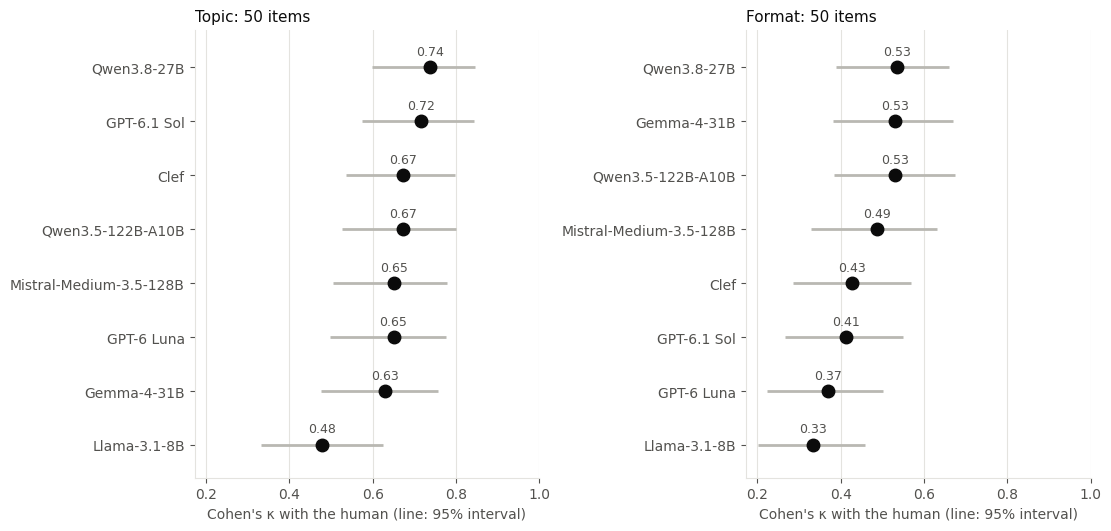

In [8]:
if human_rows:
    fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(11, 0.45 * len(compared_models) + 1.6), sharex=True,
                             constrained_layout=True)
    # One axis range for both panels, so topic and format can be compared by eye.
    lowest = min(0.4, human_agreement["kappa low"].min() - 0.03)
    for ax, label_type in zip(np.atleast_1d(axes), LABEL_TYPES):
        part = human_agreement[human_agreement["label type"] == label_type].sort_values("kappa")
        rows = np.arange(len(part))
        ax.hlines(rows, part["kappa low"], part["kappa high"], color="#b9b8b2", linewidth=2)
        ax.plot(part["kappa"], rows, "o", markersize=9, color=INK)
        for row, value in zip(rows, part["kappa"]):
            ax.annotate(f"{value:.2f}", (value, row), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color=MUTED)
        ax.set_yticks(rows, part["model"])
        ax.set_ylim(-0.6, len(part) - 0.3)
        ax.set_xlim(lowest, 1.0)
        ax.set_xlabel("Cohen's κ with the human (line: 95% interval)")
        ax.set_title(f"{label_type.capitalize()}: {int(part['items'].iloc[0])} items", loc="left")
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
    plt.show()

### Pages where most models disagree with the human

For each page the human labelled, how many of the models chose the human's label. Pages
where fewer than half did are listed with the label most models chose instead. These
are the pages worth a second look: either the page is ambiguous, the label definitions
leave room for both readings, or the human label is debatable. They are *not* evidence
that the models are wrong.

In [9]:
for label_type in LABEL_TYPES if human_rows else ():
    rows = []
    for language in human_languages:
        human = annotations.get((REFERENCE_ANNOTATOR, label_type, language), {})
        voters = [model for model in compared_models if (model, label_type, language) in annotations]
        for doc_id, human_label in human.items():
            votes = [annotations[(model, label_type, language)][doc_id] for model in voters
                     if doc_id in annotations[(model, label_type, language)]]
            agreeing = sum(vote == human_label for vote in votes)
            if votes and agreeing < len(votes) / 2:
                top_label, top_count = Counter(votes).most_common(1)[0]
                text = " ".join(texts[language][doc_id].split())
                rows.append({
                    "models agreeing": f"{agreeing} of {len(votes)}", "_order": agreeing / len(votes),
                    "human": human_label, "most models": f"{top_label} ({top_count})",
                    "page (start)": text[:SNIPPET_CHARS] + ("…" if len(text) > SNIPPET_CHARS else ""),
                })
    total = sum(len(annotations.get((REFERENCE_ANNOTATOR, label_type, language), {})) for language in human_languages)
    print(f"{label_type}: on {len(rows)} of {total} pages fewer than half of the {len(compared_models)} models chose the human's label")
    if rows:
        display(pd.DataFrame(rows).sort_values("_order").drop(columns="_order").reset_index(drop=True))

topic: on 15 of 50 pages fewer than half of the 8 models chose the human's label


,models agreeing,human,most models,page (start)
0,0 of 8,Art & Design,Entertainment (6),"Liam Williams' debut play about a young couple packs an emotional punch A boy and a girl are in bed together, in the post-coital messiness of their third coupling. Only you quickly realise that that doesn't quite sum up the situation. Because here the boy Ben, is played by a woman (Lydia Larson) whi…"
1,0 of 8,Software,Education & Jobs (8),"Punctuation on the SMARTBoard Saves Grandma Well, that's a silly title to a blog post. How can punctuation save Grandma? This saying comes from a picture I saw on Facebook. It should remind all teachers why we do what we do…we're out there trying to save Grandma! After I saw this picture, I was moti…"
2,0 of 8,History,Entertainment (5),"Welcome to Barf Town: Population All The Barfs. At how many of his photoshoots do you think Terry Richardson says ""We should do one where we're making out, that would be great!""? Is it 100% of the photoshoots, or is it more than 100%? I'm not saying the Nazis were right to burn books, I'm not saying…"
3,0 of 8,Health,Politics (8),"Category Archives: Learn On Monday, March 16, the Baker-Polito Administration announced economic support for small businesses with a $10 million loan fund to provide financial relief to those that have been affected by COVID-19. The $10 million Small Business Recovery Loan Fund will provide emergenc…"
4,0 of 8,Hardware,Science & Tech. (8),"Clipping interesting articles & photos The A.I. Revolution Is On This article seems to be saying that normal robotics and software (usually involving large databases) is artificial intelligence, which is misleading. If artificial intelligence was not achieved and the field has slowed down or nearly …"
5,0 of 8,Education & Jobs,Health (8),Abigail R.A. Aiken held postdoctoral and lecturer positions at the Office of Population Research and Woodrow Wilson School of Public and International Affairs at Princeton University before joining The University of Texas in 2016. She is currently an assistant professor of public affairs at the LBJ …
6,0 of 8,Social Life,Science & Tech. (5),"The City of Monash and Fonterra are proud to again present the Youth Award for 2012. This award recognises an individual or group of young people of secondary school age who has demonstrated leadership contributing to environmental action, awareness or research within the City of Monash. There will …"
7,0 of 8,Politics,Entertainment (4),"Donald Marquand was the Temporary Representative to the planet Abraxas Archon Zone during the late T.C. 4600s. Amidst a climate of reconciliatory policies between the Immigrant Fleet and the Galaxy Federation, he was suspected of controlling a far right-wing organization in favor of the Federation. …"
8,0 of 8,Social Life,Entertainment (8),"After all is said and done You've never walked, you've never run, You're a winner You got the moves, you know the streets Break the rules, take the heat You're nobody's fool You're at your best when when the goin' gets rough You've been put to the test, but it's never enough never bend, you never br…"
9,1 of 8,Literature,Entertainment (5),"Friday, 17 April 2009 What makes music appealing? Can a person find a piece of sound that is known as music appealing without any reference to the cultural laden baggage that accompanies it? Is it possible ? Can a person find a series of sounds appealing in one cultural context but when listened in …"


format: on 23 of 50 pages fewer than half of the 8 models chose the human's label


,models agreeing,human,most models,page (start)
0,0 of 8,About (Org.),Truncated (5),"lot happens in your child's mouth from infancy to early adulthood. Not surprisingly, it's the most active period for development of teeth, gums and jaw structure. Our primary goal as care providers is to keep that development on track. One of our main concerns, therefore, is to protect their teeth a…"
1,0 of 8,Product Page,About (Org.) (6),"A-11: Mrs. Mitera In A-11, our goal is for each student to work on increasing their level of independence in every aspect of their life while having fun and learning from their peers and staff. In the classroom, we will explore and increase the knowledge of functional vocabulary words. Additionally,…"
2,0 of 8,Content Listing,Spam / Ads (7),"how do you crush lizenithne calculate crush stone volume Gravel calculator to help you estimate how much gravel you will need to cover ... guide, but will help you approximate the likely volume of gravel or slate needed. ... pebbles, slate, granite, rockery stone, glass aggregates and garden feature…"
3,0 of 8,Q&A Forum,Comment Section (8),"Posted 2019-11-13 12:27:54 @DemariusDice This is a Samsung, not a Toshiba... Also, for console gaming, it's worth noting that none of the Samsung TVs support Dolby-Vision HDR, which seems to be the favored HDR format for the next console generation - they will support standard HDR10, too, of course,…"
4,0 of 8,Product Page,Customer Support (4),"If you already have a prescription from your prescriber, click the product below to purchase the medication. - Malarone, Doxycycline or Lariam. SYMPTOMS OF MALARIA: Malignant malaria (Plasmodium falciparum) can develop from eight days after being bitten by a mosquito and the benign form (Plasmodium …"
5,0 of 8,Listicle,News Article (8),"Preferred shares of long-distance carrier Embratel , which are down about 40% on the year, rose 4.3% to 31.30 reals, while Telesp Celular 's preferred shares continued to recover from recent weakness, moving 6.5% higher to 23.10 reals. Despite the market's positive tone, oil giant Petrobras ' prefer…"
6,0 of 8,About (Org.),Product Page (3),"VDI has always faced an uphill slog. Implementation is time-consuming and expensive. The technology only fits certain use cases, and with so many moving parts and people to please, a lot of problems can crop up. If your higher-ups are on board with doing VDI and you get the infrastructure right, one…"
7,0 of 8,Nonfiction Writing,Product Page (8),"This book expands that list and highlights his most significant contributions to history, including: His role in the creation of the Panama Canal How he ended the Russo-Japanese War His ""trust busting,"" which brought corporations under the control of the people The impact of his conservation efforts…"
8,0 of 8,Nonfiction Writing,Truncated (3),"That Time Eric Matthews Dated Taylor Swift No, not the actual Taylor Swift. But the internet has discovered the striking resemblance between Taylor and Corinna, a.k.a the musician on Boy Meets World that writes a super mean song about Eric because he broke her heart. And it's GREAT."
9,0 of 8,Creative Writing,Truncated (5),"by Johnny Krüger on a young sacred birman cat Birman Cat - The great thing about a Birman is how balanced the cat is on its personality. They are definitely a ""people's cat"" who bond with their owners. They have a curious nature and are one of the most intelligent cats"


## 5. Agreement per language

The same measures for the focus pair, separately for each language (100 documents
each). With 100 items, a difference of a few points between languages is within noise:
one document is one percentage point of agreement.

The plot shows κ and macro F1 per language. Both are on the same 0–1 scale; the axis is
zoomed to the range of the data, so read the differences from the axis, not from the
distances.

agreement        kappa        macro F1        weighted F1       
label type    format topic format  topic   format  topic      format  topic
language                                                                   
english         0.84  0.89  0.829  0.881    0.791  0.852       0.854  0.889
finnish         0.79  0.88  0.778  0.870    0.769  0.833       0.785  0.883
german          0.78  0.85  0.767  0.838    0.749  0.800       0.767  0.845
hungarian       0.80  0.87  0.787  0.860    0.738  0.863       0.795  0.874
icelandic       0.78  0.83  0.767  0.816    0.757  0.765       0.776  0.841
ukrainian       0.78  0.88  0.766  0.870    0.771  0.843       0.775  0.889

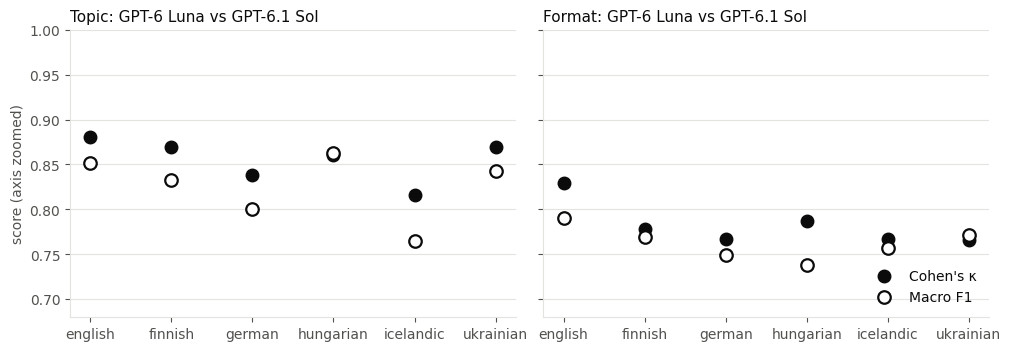

In [10]:
first, second = FOCUS_PAIR
language_rows = []
for label_type in LABEL_TYPES:
    for language in LANGUAGES:
        items = shared_items(first, second, label_type, languages=(language,))
        if not items:
            continue
        scores = agreement_scores(confusion_matrix([(a, b) for *_, a, b in items], label_type))
        language_rows.append({"label type": label_type, "language": language, "items": len(items),
                              **{name: round(value, 3) for name, value in scores.items()}})
by_language = pd.DataFrame(language_rows)
display(by_language.pivot(index="language", columns="label type", values=["agreement", "kappa", "macro F1", "weighted F1"])
        .reindex(LANGUAGES).dropna(how="all"))

fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(10, 3.4), sharey=True, constrained_layout=True)
low = min(by_language["kappa"].min(), by_language["macro F1"].min())
for ax, label_type in zip(np.atleast_1d(axes), LABEL_TYPES):
    part = by_language[by_language["label type"] == label_type]
    positions = np.arange(len(part))
    # Marker fill, not colour, tells the two measures apart (colour is reserved for annotators).
    ax.plot(positions, part["kappa"], "o", markersize=9, color=INK, label="Cohen's κ")
    ax.plot(positions, part["macro F1"], "o", markersize=9, markerfacecolor="white", markeredgecolor=INK,
            markeredgewidth=1.6, label="Macro F1")
    ax.set_xticks(positions, part["language"])
    ax.set_title(f"{label_type.capitalize()}: {first} vs {second}", loc="left")
    ax.set_ylim(np.floor(low * 20) / 20 - 0.02, 1.0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
np.atleast_1d(axes)[0].set_ylabel("score (axis zoomed)")
np.atleast_1d(axes)[-1].legend(frameon=False, loc="lower right")
plt.show()

## 6. Agreement per label, and how often each annotator uses each label

**Table:** for every label used by the focus pair, how often each annotator chose it
(over all languages), how often both chose it for the same item, and the label's F1.
Rows are sorted from the lowest F1. Labels with a handful of uses have unstable F1
values: with five uses, a single item moves F1 by about 0.2.

**Plot:** each label's count for the two annotators, joined by a line. A long line
means one annotator uses the label much more than the other, which is a difference in
how they read the label definition rather than random noise.

In [11]:
usage: dict[str, pd.DataFrame] = {}
for label_type in LABEL_TYPES:
    items = shared_items(first, second, label_type)
    matrix = confusion_matrix([(a, b) for *_, a, b in items], label_type)
    count_first, count_second, both = matrix.sum(axis=1), matrix.sum(axis=0), np.diag(matrix)
    table = pd.DataFrame({first: count_first, second: count_second, "both": both}, index=label_names[label_type])
    table = table[(table[first] + table[second]) > 0]
    table["F1"] = (2 * table["both"] / (table[first] + table[second])).round(2)
    usage[label_type] = table
    print(f"{label_type}: {len(table)} of {len(label_names[label_type])} labels used; "
          f"never used by either: {', '.join(sorted(set(label_names[label_type]) - set(table.index))) or 'none'}")
    display(table.sort_values("F1"))

topic: 22 of 26 labels used; never used by either: Adult, Crime & Law, Other, Travel


,GPT-6 Luna,GPT-6.1 Sol,both,F1
Art & Design,5,9,0,0.00
Social Life,6,12,6,0.67
Entertainment,69,51,45,0.75
Hardware,12,12,9,0.75
Transportation,10,6,6,0.75
History,17,14,12,0.77
Games,15,24,15,0.77
Finance & Business,21,26,19,0.81
Industrial,26,18,18,0.82
Education & Jobs,40,51,38,0.84


format: 23 of 26 labels used; never used by either: Audio Transcript, Documentation, Legal Notices


,GPT-6 Luna,GPT-6.1 Sol,both,F1
About (Pers.),0,1,0,0.00
User Review,8,2,1,0.20
Tutorial,16,16,10,0.62
Other,7,9,5,0.62
Structured Data,6,13,6,0.63
Customer Support,15,13,9,0.64
Knowledge Article,48,29,25,0.65
Comment Section,32,40,25,0.69
Q&A Forum,56,42,36,0.73
Nonfiction Writing,35,28,24,0.76


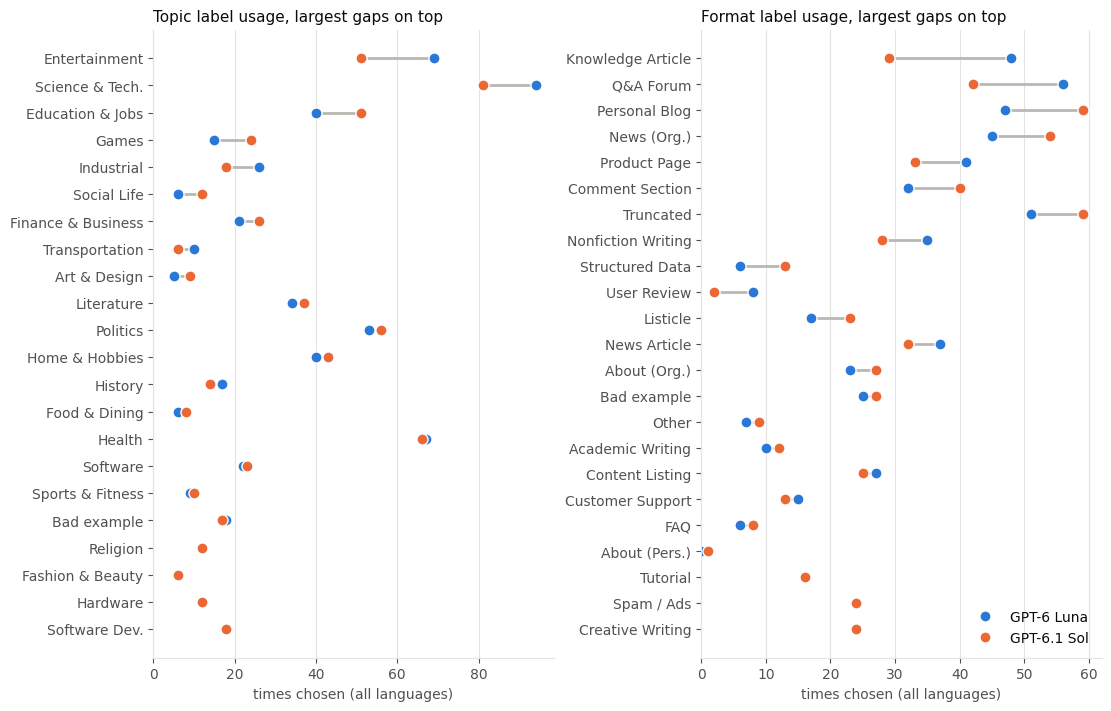

In [12]:
fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(11, 7), constrained_layout=True)
for ax, label_type in zip(np.atleast_1d(axes), LABEL_TYPES):
    table = usage[label_type].assign(gap=lambda t: (t[first] - t[second]).abs()).sort_values("gap")
    rows = np.arange(len(table))
    ax.hlines(rows, table[[first, second]].min(axis=1), table[[first, second]].max(axis=1), color="#b9b8b2", linewidth=2)
    for annotator in (first, second):
        ax.plot(table[annotator], rows, "o", markersize=8, color=COLORS[annotator], markeredgecolor="white",
                markeredgewidth=1, label=annotator)
    ax.set_yticks(rows, table.index)
    ax.set_xlabel("times chosen (all languages)")
    ax.set_title(f"{label_type.capitalize()} label usage, largest gaps on top", loc="left")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlim(left=0)
np.atleast_1d(axes)[-1].legend(frameon=False, loc="lower right")
plt.show()

## 7. Which labels get confused

**Table:** the most frequent disagreements, as "first annotator's label → second
annotator's label".

**Heatmap:** all disagreements of the focus pair. Rows are the first annotator's
label, columns the second's; a cell counts the items with that combination. Agreements
(the diagonal) are left out so the disagreements are visible, and only labels involved
in at least one disagreement are shown. A cell and its mirror image both being filled
(e.g. A→B and B→A) means the two labels are confused in both directions; a filled cell
with an empty mirror means one annotator systematically prefers the other label.

In [13]:
confusions: dict[str, pd.DataFrame] = {}
for label_type in LABEL_TYPES:
    items = shared_items(first, second, label_type)
    counts = Counter((a, b) for *_, a, b in items if a != b)
    table = pd.DataFrame([{first: a, second: b, "items": n} for (a, b), n in counts.most_common()])
    confusions[label_type] = table
    print(f"{label_type}: {sum(counts.values())} disagreements in {len(items)} items, {len(counts)} distinct label pairs")
    display(table.head(10))

topic: 80 disagreements in 600 items, 33 distinct label pairs


,GPT-6 Luna,GPT-6.1 Sol,items
0,Entertainment,Art & Design,8
1,Science & Tech.,Politics,7
2,Entertainment,Social Life,6
3,Entertainment,Games,6
4,History,Education & Jobs,5
5,Industrial,Education & Jobs,5
6,Science & Tech.,Finance & Business,4
7,Art & Design,Entertainment,3
8,Hardware,Software,3
9,Politics,Entertainment,3


format: 123 disagreements in 600 items, 57 distinct label pairs


,GPT-6 Luna,GPT-6.1 Sol,items
0,Q&A Forum,Comment Section,11
1,Nonfiction Writing,Personal Blog,7
2,Product Page,Structured Data,6
3,Knowledge Article,Listicle,5
4,Comment Section,Q&A Forum,5
5,User Review,Comment Section,4
6,Nonfiction Writing,Truncated,4
7,News Article,Truncated,4
8,Knowledge Article,About (Org.),4
9,Customer Support,News (Org.),3


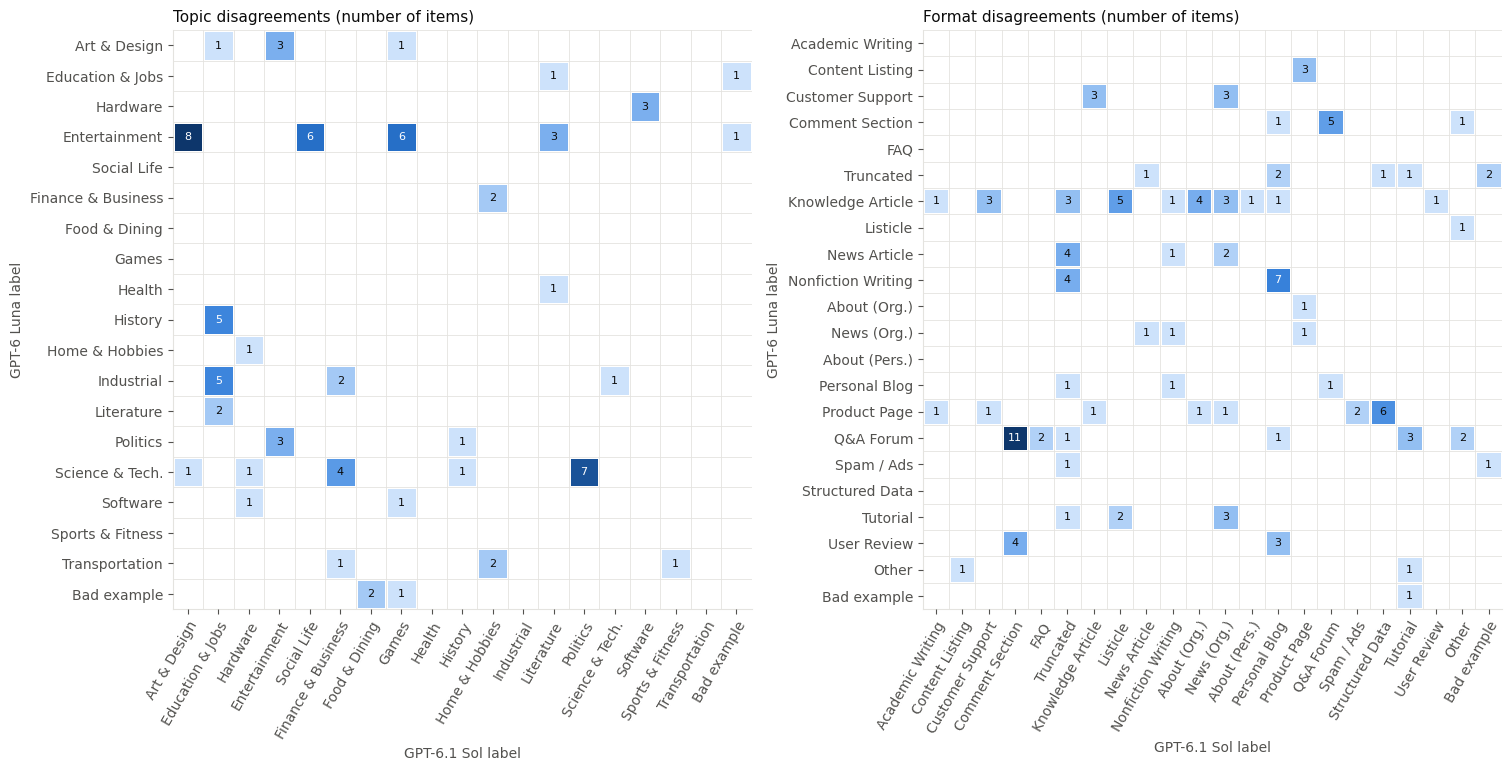

In [14]:
fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(15, 7.5), constrained_layout=True)
for ax, label_type in zip(np.atleast_1d(axes), LABEL_TYPES):
    items = shared_items(first, second, label_type)
    matrix = confusion_matrix([(a, b) for *_, a, b in items], label_type)
    np.fill_diagonal(matrix, 0)
    names = np.array(label_names[label_type])
    keep = (matrix.sum(axis=0) + matrix.sum(axis=1)) > 0
    shown = matrix[np.ix_(keep, keep)]
    # Empty cells stay white; counts use a single-hue ramp from light to dark. Cells are
    # drawn as a mesh with a white gap around each.
    size = int(keep.sum())
    ax.pcolormesh(np.ma.masked_equal(shown, 0), cmap=BLUES, vmin=1, vmax=max(shown.max(), 2),
                  edgecolors="white", linewidth=2)
    for row, col in zip(*np.nonzero(shown)):
        ax.text(col + 0.5, row + 0.5, shown[row, col], ha="center", va="center", fontsize=8,
                color="white" if shown[row, col] > 0.55 * shown.max() else INK)
    ax.set_xticks(np.arange(size) + 0.5, names[keep], rotation=60, ha="right", rotation_mode="anchor")
    ax.set_yticks(np.arange(size) + 0.5, names[keep])
    ax.set_xticks(np.arange(size + 1), minor=True)
    ax.set_yticks(np.arange(size + 1), minor=True)
    # The grid is drawn over the mesh (whose white edges would hide it) and runs
    # inside the white gaps, so it never crosses a number.
    ax.grid(which="minor", color=GRID, linewidth=0.6)
    ax.set_axisbelow(False)
    ax.tick_params(which="minor", length=0)
    ax.set_xlim(0, size)
    ax.set_ylim(size, 0)          # first label on top, like a table
    ax.set_aspect("equal")
    ax.set_xlabel(f"{second} label")
    ax.set_ylabel(f"{first} label")
    ax.set_title(f"{label_type.capitalize()} disagreements (number of items)", loc="left")
plt.show()

## 8. Consistency across languages

A parallel document should get the same label in every language. This section asks
two things:

1. **How consistent is each annotator with itself?** The share of documents that get
   one and the same label in all languages the annotator labelled (documents not
   labelled in every one of those languages are left out).
2. **Are the pair's disagreements about the document or about the translation?** For
   each document, in how many languages do the two annotators disagree. A disagreement
   in every language reflects a different reading of the page or of the label
   definitions. A disagreement in only some languages means at least one annotator
   changed its answer between translations.

In [15]:
consistency_rows = []
for annotator in annotators:
    for label_type in LABEL_TYPES:
        available = [language for language in LANGUAGES if (annotator, label_type, language) in annotations]
        if len(available) < 2:
            continue
        per_document: dict[str, list[str]] = {}
        for language in available:
            for doc_id, label in annotations[(annotator, label_type, language)].items():
                per_document.setdefault(doc_id, []).append(label)
        complete = [labels for labels in per_document.values() if len(labels) == len(available)]
        distinct = [len(set(labels)) for labels in complete]
        consistency_rows.append({
            "annotator": annotator, "label type": label_type, "languages": len(available), "documents": len(complete),
            "same label in all languages": round(float(np.mean([n == 1 for n in distinct])), 3),
            "two labels": round(float(np.mean([n == 2 for n in distinct])), 3),
            "three or more": round(float(np.mean([n >= 3 for n in distinct])), 3),
        })
display(pd.DataFrame(consistency_rows))

persistence_rows = []
for label_type in LABEL_TYPES:
    items = shared_items(first, second, label_type)
    languages_per_document = Counter(doc_id for _, doc_id, _, _ in items)
    disagreements = Counter(doc_id for _, doc_id, a, b in items if a != b)
    histogram = Counter(disagreements.values())
    persistence_rows.append({
        "label type": label_type, "documents": len(languages_per_document),
        "no disagreement": len(languages_per_document) - len(disagreements),
        **{f"in {n} language{'s' if n > 1 else ''}": histogram.get(n, 0) for n in range(1, max(languages_per_document.values()) + 1)},
        "in every language": sum(disagreements[doc_id] == languages_per_document[doc_id] for doc_id in disagreements),
    })
print(f"Documents by the number of languages in which {first} and {second} disagree:")
display(pd.DataFrame(persistence_rows))

,annotator,label type,languages,documents,same label in all languages,two labels,three or more
0,GPT-6 Luna,topic,6,100,0.79,0.18,0.03
1,GPT-6 Luna,format,6,100,0.57,0.34,0.09
2,GPT-6.1 Sol,topic,6,100,0.90,0.08,0.02
3,GPT-6.1 Sol,format,6,100,0.75,0.16,0.09


Documents by the number of languages in which GPT-6 Luna and GPT-6.1 Sol disagree:


,label type,documents,no disagreement,in 1 language,in 2 languages,in 3 languages,in 4 languages,in 5 languages,in 6 languages,in every language
0,topic,100,73,10,5,1,4,1,6,6
1,format,100,52,18,6,11,6,6,1,1


## 9. Example disagreements

Numbers don't show *why* two annotators disagree. This table lists English items where
the focus pair chose different labels, with the start of the page and each annotator's
explanation, taking the most frequent label confusions first (one example per
confusion). Change `EXAMPLE_LANGUAGE` to read examples in another language, or
`EXAMPLES_SHOWN` in the parameters for more rows. An annotator without explanations
(the human) shows only the label.

In [16]:
EXAMPLE_LANGUAGE = "english"

for label_type in LABEL_TYPES:
    items = shared_items(first, second, label_type, languages=(EXAMPLE_LANGUAGE,))
    disagreements = [(doc_id, a, b) for _, doc_id, a, b in items if a != b]
    frequency = Counter((a, b) for _, a, b in disagreements)
    seen, rows = set(), []
    # Most frequent confusions first, one example each.
    for doc_id, a, b in sorted(disagreements, key=lambda item: (-frequency[(item[1], item[2])], item[0])):
        if (a, b) in seen:
            continue
        seen.add((a, b))
        text = " ".join(texts[EXAMPLE_LANGUAGE][doc_id].split())
        rows.append({
            "page (start)": text[:SNIPPET_CHARS] + ("…" if len(text) > SNIPPET_CHARS else ""),
            first: f"{a}: {explanations.get((first, label_type, EXAMPLE_LANGUAGE), {}).get(doc_id, '')}".rstrip(": "),
            second: f"{b}: {explanations.get((second, label_type, EXAMPLE_LANGUAGE), {}).get(doc_id, '')}".rstrip(": "),
        })
    print(f"{label_type}: {len(disagreements)} disagreements in {len(items)} {EXAMPLE_LANGUAGE} items; "
          f"showing {min(EXAMPLES_SHOWN, len(rows))}")
    display(pd.DataFrame(rows[:EXAMPLES_SHOWN]))

topic: 11 disagreements in 100 english items; showing 8


,page (start),GPT-6 Luna,GPT-6.1 Sol
0,"The 2020 inaugural competition for secondary school students investigating the Australian Lebanese story Unfortunately, Covid-19 seriously disrupted the inaugural Australian Lebanese Historical Society Competition for Secondary School Students. During 2020, teachers right across Australia have had t…",History: The page focuses on documenting Australian Lebanese history and family heritage.,Education & Jobs: The page primarily discusses a secondary-school competition and its postponement due to COVID-19 disruptions to teaching and student workloads.
1,"We use cookies to allow us and selected partners to improve your experience and our advertising. By continuing to browse you consent to our use of cookies. You can understand more and change your cookies preferences here. Construction and The Built Environment Entry requirements Sorry, no informatio…","Industrial: The course focuses on construction methods, materials, surveying, and project operations, which are industrial topics.","Education & Jobs: The page describes a vocational qualification, including course structure, modules, assessment methods, and career progression in construction."
2,"Welcome to Barf Town: Population All The Barfs. At how many of his photoshoots do you think Terry Richardson says ""We should do one where we're making out, that would be great!""? Is it 100% of the photoshoots, or is it more than 100%? I'm not saying the Nazis were right to burn books, I'm not saying…","Art & Design: The page criticizes Terry Richardson’s photography and photoshoot style, making art and design the best fit.","Entertainment: The page offers humorous, sarcastic commentary about celebrity photographer Terry Richardson and his photoshoots."
3,"Table of contents: What is an example of a closed question? For example, in standard parlance, ""Is it ever right to lie?"" would be regarded as a closed question: it elicits a yes–no response. ... Any initial yes–no answer to it can be ""opened up"" by the questioner (""Why do you think that?"", ""Could t…","Education & Jobs: The page explains open and closed questions and their use in course evaluations, making it educational content.","Literature: The page explains open, closed, and yes–no questions, focusing on their linguistic forms and meanings."
4,"VDI has always faced an uphill slog. Implementation is time-consuming and expensive. The technology only fits certain use cases, and with so many moving parts and people to please, a lot of problems can crop up. If your higher-ups are on board with doing VDI and you get the infrastructure right, one…",Hardware: The page focuses on GPU hardware options for improving graphics performance in virtual desktop environments.,"Software: The page discusses deploying virtual desktops and improving application performance through GPU emulation, virtualization, and sharing."
5,English to Hindi Meaning :: aids Show English Meaning (+) Noun(1) a person or thing that is a resource that helps make something easier or possible to do(2) the activity of contributing to the fulfillment of a need or furtherance of an effort or purpose(3) gift of money or other material help to sup…,"Health: The page focuses on the meaning and Hindi translation of AIDS, a health-related topic.","Literature: The page focuses on English-to-Hindi translation, word meanings, and pronunciation, which fall under linguistics."
6,"Friday, 17 April 2009 What makes music appealing? Can a person find a piece of sound that is known as music appealing without any reference to the cultural laden baggage that accompanies it? Is it possible ? Can a person find a series of sounds appealing in one cultural context but when listened in …","Entertainment: The page focuses on music and listeners’ reactions to an album, so Entertainment is the best fit.","Art & Design: The page explores musical appreciation and how cultural context influences aesthetic judgments, discussing music as art rather than entert

format: 16 disagreements in 100 english items; showing 8


,page (start),GPT-6 Luna,GPT-6.1 Sol
0,"Sheep's Milk and Its Benefits For thousands of years, there have been a few animals that humans have relied upon for their source of milk which includes cows, buffalo, goats, and sheep. For the most part, the popularity of the milk has been determined by the number of animals in the area which is wh…","Knowledge Article: The page is an informational article explaining sheep’s milk and its purported benefits, rather than a personal essay, tutorial, or product promotion.","Listicle: The article presents sheep’s milk benefits as a list of labeled sections, including vitamins, minerals, proteins, immune support, and lactose tolerance."
1,Actions from stephanie902Movable Type Pro 4.382012-08-26T11:02:00Z on Prop 38 Cheat Sheet: Molly Munger's Tax for Education in Elections 2012tag: Your ignorance astounds me! You are obviously not familiar with Americas history. If you paid enough attention in class you would have caught the fact tha…,Comment Section: This is a user comment responding to a blog post; the metadata and conversational tone indicate a comment-section format.,"Other: The content is a single user comment with feed metadata, rather than a discussion page containing multiple posts or comments."
2,"Yeah, you could look at it that way, but it is specifying ""wyif"" (with yarn in front) because it is on a knit row. So you K6, with yarn in back as you always would to knit, then move the yarn forward and slip 2 stitches, etc.",Bad example: The text is a single conversational fragment without enough context or multiple posts to identify a page format.,"Tutorial: The text gives practical knitting instructions, explaining when to move the yarn forward and slip stitches."
3,"Full-Depth Reclamation using Portland Cement: A Study of Long-Term Performance Full-Depth Reclamation (FDR) with cement is a procedure where failed asphalt pavements are pulverized and reclaimed, using cement to stabilize the recycled materials and create a new pavement base. This cementstabilized b…","Product Page: This is a brief description of a specific report, presented like a publication or product page.","Academic Writing: The text is a research report abstract summarizing a pavement-performance study, including its scope, sample size, and project ages."
4,"there are a few lilies known as bella donnas, make sure you take a pic with you and ASK a florist in person with the pic so she knows which lily you are after. As a florist I have brides insisting that there are dark blue roses becuase you can get silk ones!!! I have to tell them no there are no dar…","Q&A Forum: This reads like a user’s answer to a question, offering direct advice in a Q&A forum style.","Other: The text is a single informal advice comment, not a full guide or an explicit Q&A exchange. It lacks the multiple posts required for a discussion forum classification."
5,"I know that $\epsilon, 0, 1, 00, 11, 010, 101, 01010, 10101, 10001, 01110$ all fit the grammar, but I can't find a formal way to express what I want to say. Perhaps I don't know the symbols or something, but I would express it as $\begingroup$@YuvalFilmus a palindrome always has an even number of di…","Comment Section: The page content consists of multiple user comments in a discussion thread, rather than a complete question-and-answer exchange.","Q&A Forum: The page contains a user's mathematical question and follow-up exchanges in a Stack Exchange-style Q&A forum, including a reference to accepting an answer."
6,"Behind the development of the 300 SL between 1951 and 1954 and the construction of the successful 300 SLR racing sports car was the inspiration of a man who was to become known as the technical brains behind the Silver Arrows: Rudolf Uhlenhaut. Uhlenhaut was an engineer with petrol in his blood, but…","News (Org.): This is an organization-published historical feature about Rudolf Uhlenhaut and the Mercedes-Benz 300 SLR, presented as an editorial post.","Nonfiction Writing: T

## 10. An open model against an OpenAI model

The open model that will label the full dataset should behave like the strongest
commercial model available, at a fraction of the cost. This section compares the two
models of `OPEN_FOCUS_PAIR` on all 100 documents in all six languages.

**Agreement.** The first table gives the pair's overall agreement, with the other
pairs among these models and the OpenAI models for scale: if the open model agrees
with an OpenAI model about as well as the two OpenAI models agree with each other, it
is within the spread of the commercial models. The second table gives the pair's
agreement per language.

In [17]:
open_model, api_model = OPEN_FOCUS_PAIR
for name in OPEN_FOCUS_PAIR:
    assert any(key[0] == name for key in annotations), f"OPEN_FOCUS_PAIR model {name!r} has no labels"

scale_models = [open_model, *API_MODELS]
pair_rows = []
for label_type in LABEL_TYPES:
    for model_a, model_b in combinations(scale_models, 2):
        items = shared_items(model_a, model_b, label_type)
        scores = agreement_scores(confusion_matrix([(a, b) for *_, a, b in items], label_type))
        intervals = bootstrap_intervals(items, label_type)
        row = {"label type": label_type, "pair": f"{model_a} vs {model_b}", "items": len(items)}
        for name in ("agreement", "kappa", "macro F1"):
            row[name] = round(scores[name], 3)
            row[f"{name} 95% CI"] = f"{intervals[name][0]:.3f}–{intervals[name][1]:.3f}"
        pair_rows.append(row)
open_pairs = pd.DataFrame(pair_rows)
display(open_pairs)

open_language_rows = []
for label_type in LABEL_TYPES:
    for language in LANGUAGES:
        items = shared_items(open_model, api_model, label_type, languages=(language,))
        if not items:
            continue
        scores = agreement_scores(confusion_matrix([(a, b) for *_, a, b in items], label_type))
        open_language_rows.append({"label type": label_type, "language": language, "items": len(items),
                                   **{name: round(scores[name], 3) for name in ("agreement", "kappa", "macro F1")}})
print(f"{open_model} vs {api_model}, per language:")
display(pd.DataFrame(open_language_rows).pivot(index="language", columns="label type", values=["agreement", "kappa", "macro F1"])
        .reindex(LANGUAGES).dropna(how="all"))

,label type,pair,items,agreement,agreement 95% CI,kappa,kappa 95% CI,macro F1,macro F1 95% CI
0,topic,Qwen3.8-27B vs GPT-6 Luna,600,0.880,0.828–0.925,0.870,0.812–0.918,0.820,0.662–0.862
1,topic,Qwen3.8-27B vs GPT-6.1 Sol,600,0.853,0.792–0.908,0.841,0.774–0.901,0.794,0.655–0.849
2,topic,GPT-6 Luna vs GPT-6.1 Sol,600,0.867,0.810–0.917,0.856,0.794–0.909,0.824,0.699–0.862
3,format,Qwen3.8-27B vs GPT-6 Luna,600,0.697,0.633–0.758,0.678,0.609–0.740,0.617,0.529–0.693
4,format,Qwen3.8-27B vs GPT-6.1 Sol,600,0.700,0.633–0.770,0.682,0.609–0.753,0.634,0.544–0.702
5,format,GPT-6 Luna vs GPT-6.1 Sol,600,0.795,0.742–0.845,0.782,0.724–0.835,0.734,0.626–0.790


Qwen3.8-27B vs GPT-6.1 Sol, per language:


agreement        kappa        macro F1       
label type    format topic format  topic   format  topic
language                                                
english         0.75  0.86  0.735  0.848    0.670  0.763
finnish         0.69  0.87  0.671  0.860    0.668  0.833
german          0.71  0.87  0.693  0.859    0.659  0.810
hungarian       0.68  0.84  0.660  0.827    0.667  0.806
icelandic       0.69  0.80  0.671  0.784    0.630  0.716
ukrainian       0.68  0.88  0.661  0.870    0.606  0.837

**Where the two differ.** Three views of the same disagreements:

- **Consistency across languages:** the share of documents that get the same label in
  all six languages, per model (as in section 8).
- **Label usage:** the labels whose counts differ most between the two models. A large
  gap is a difference in how the models read a label definition.
- **Confusions:** the most frequent "open model's label → OpenAI model's label" pairs.

In [18]:
consistency_open = []
for label_type in LABEL_TYPES:
    for model in OPEN_FOCUS_PAIR:
        available = [language for language in LANGUAGES if (model, label_type, language) in annotations]
        documents = set.intersection(*(set(annotations[(model, label_type, language)]) for language in available))
        same = [len({annotations[(model, label_type, language)][doc_id] for language in available}) == 1 for doc_id in documents]
        consistency_open.append({"label type": label_type, "model": model, "languages": len(available),
                                 "documents": len(documents), "same label in all languages": round(float(np.mean(same)), 3)})
display(pd.DataFrame(consistency_open))

open_confusions: dict[str, pd.DataFrame] = {}
for label_type in LABEL_TYPES:
    items = shared_items(open_model, api_model, label_type)
    matrix = confusion_matrix([(a, b) for *_, a, b in items], label_type)
    usage_gap = pd.DataFrame({open_model: matrix.sum(axis=1), api_model: matrix.sum(axis=0)}, index=label_names[label_type])
    usage_gap["difference"] = usage_gap[open_model] - usage_gap[api_model]
    counts = Counter((a, b) for *_, a, b in items if a != b)
    open_confusions[label_type] = pd.DataFrame([{open_model: a, api_model: b, "items": n} for (a, b), n in counts.most_common()])
    documents = Counter(doc_id for _, doc_id, a, b in items if a != b)
    print(f"{label_type}: {sum(counts.values())} disagreements in {len(items)} items, on {len(documents)} documents "
          f"({sum(n == len(LANGUAGES) for n in documents.values())} of them in every language)")
    print("largest differences in label usage:")
    display(usage_gap.reindex(usage_gap["difference"].abs().sort_values(ascending=False).index).head(8))
    print("most frequent disagreements:")
    display(open_confusions[label_type].head(8))

,label type,model,languages,documents,same label in all languages
0,topic,Qwen3.8-27B,6,100,0.85
1,topic,GPT-6.1 Sol,6,100,0.90
2,format,Qwen3.8-27B,6,100,0.54
3,format,GPT-6.1 Sol,6,100,0.75


topic: 88 disagreements in 600 items, on 25 documents (5 of them in every language)
largest differences in label usage:


,Qwen3.8-27B,GPT-6.1 Sol,difference
Entertainment,74,51,23
Games,9,24,-15
Science & Tech.,96,81,15
Politics,44,56,-12
Art & Design,0,9,-9
Literature,29,37,-8
Health,59,66,-7
Software Dev.,24,18,6


most frequent disagreements:


,Qwen3.8-27B,GPT-6.1 Sol,items
0,Entertainment,Art & Design,9
1,Science & Tech.,Politics,6
2,Finance & Business,Politics,6
3,Entertainment,Games,6
4,History,Education & Jobs,5
5,Finance & Business,Home & Hobbies,5
6,Software Dev.,Games,5
7,Entertainment,Social Life,5


format: 180 disagreements in 600 items, on 57 documents (6 of them in every language)
largest differences in label usage:


,Qwen3.8-27B,GPT-6.1 Sol,difference
Truncated,18,59,-41
Knowledge Article,58,29,29
Bad example,53,27,26
Listicle,10,23,-13
News (Org.),41,54,-13
About (Org.),14,27,-13
Product Page,41,33,8
Structured Data,6,13,-7


most frequent disagreements:


,Qwen3.8-27B,GPT-6.1 Sol,items
0,Bad example,Truncated,14
1,Personal Blog,Truncated,9
2,Nonfiction Writing,Personal Blog,8
3,Knowledge Article,Truncated,8
4,Comment Section,Other,7
5,Knowledge Article,Listicle,6
6,News Article,News (Org.),6
7,Nonfiction Writing,Truncated,6


**Against the human annotator.** On the pages the human labelled, every page falls in
one of five groups: all three agree; only the open model matches the human; only the
OpenAI model matches the human; the two models agree with each other but not with the
human; or all three differ. The second and third columns show which model is closer to
the human where the models differ; the fourth shows how often the two models share a
reading the human doesn't.

In [19]:
three_way_rows = []
for label_type in LABEL_TYPES if REFERENCE_ANNOTATOR in annotators else ():
    groups = Counter()
    for language in human_languages:
        human = annotations.get((REFERENCE_ANNOTATOR, label_type, language), {})
        open_labels, api_labels = annotations[(open_model, label_type, language)], annotations[(api_model, label_type, language)]
        for doc_id, human_label in human.items():
            open_match, api_match = open_labels[doc_id] == human_label, api_labels[doc_id] == human_label
            if open_match and api_match:
                groups["all three agree"] += 1
            elif open_match:
                groups[f"only {open_model} matches the human"] += 1
            elif api_match:
                groups[f"only {api_model} matches the human"] += 1
            elif open_labels[doc_id] == api_labels[doc_id]:
                groups["models agree, human differs"] += 1
            else:
                groups["all three differ"] += 1
    order = ["all three agree", f"only {open_model} matches the human", f"only {api_model} matches the human",
             "models agree, human differs", "all three differ"]
    three_way_rows.append({"label type": label_type, "pages": sum(groups.values()), **{name: groups[name] for name in order}})
if three_way_rows:
    display(pd.DataFrame(three_way_rows))
else:
    print(f"No labels from {REFERENCE_ANNOTATOR!r}; the three-way comparison is skipped.")

,label type,pages,all three agree,only Qwen3.8-27B matches the human,only GPT-6.1 Sol matches the human,"models agree, human differs",all three differ
0,topic,50,35,3,2,7,3
1,format,50,21,7,1,18,3


**What the open model's probabilities add.** The open model gives a probability for
every label, not only a top label. Two questions:

- **Does it know when it is unsure?** Its mean top probability on items where the two
  models agree and where they disagree. A clearly lower value on disagreements means
  the probabilities flag the doubtful items.
- **Is the OpenAI model's label its next choice?** Where the OpenAI model's label
  ranks in the open model's distribution: first (the models agree), second, or lower.
  "Within top 2" is the share of items where the OpenAI model's label is the open
  model's first or second choice. A classifier trained on the full distributions sees
  that second choice; one trained on hard labels would not.

In [20]:
probability_rows = []
for label_type in LABEL_TYPES:
    top_agree, top_disagree, ranks, api_probability = [], [], [], []
    for language, doc_id, open_label, api_label in shared_items(open_model, api_model, label_type):
        distribution = probabilities[(label_type, language)][doc_id]
        ranking = sorted(distribution, key=distribution.get, reverse=True)
        ranks.append(ranking.index(api_label) + 1)
        (top_agree if open_label == api_label else top_disagree).append(distribution[ranking[0]])
        if open_label != api_label:
            api_probability.append(distribution[api_label])
    ranks = np.array(ranks)
    probability_rows.append({
        "label type": label_type, "items": len(ranks),
        "mean top probability, models agree": round(float(np.mean(top_agree)), 3),
        "mean top probability, models disagree": round(float(np.mean(top_disagree)), 3),
        f"{api_model} label is 1st choice": round(float(np.mean(ranks == 1)), 3),
        "2nd choice": round(float(np.mean(ranks == 2)), 3),
        "3rd or lower": round(float(np.mean(ranks >= 3)), 3),
        "within top 2": round(float(np.mean(ranks <= 2)), 3),
        f"mean probability of {api_model} label on disagreements": round(float(np.mean(api_probability)), 3),
    })
open_probabilities = pd.DataFrame(probability_rows)
display(open_probabilities)

,label type,items,"mean top probability, models agree","mean top probability, models disagree",GPT-6.1 Sol label is 1st choice,2nd choice,3rd or lower,within top 2,mean probability of GPT-6.1 Sol label on disagreements
0,topic,600,0.946,0.760,0.853,0.102,0.045,0.955,0.156
1,format,600,0.844,0.614,0.700,0.167,0.133,0.867,0.168


## 11. A candidate open model against the chosen one

Is another open model a better choice than the chosen one? This section compares the
two models of `CANDIDATE_PAIR` (by default Clef, a decision model built on
Qwen3.8-27B, against Qwen3.8-27B itself) on every document both labelled: 2,000
parallel documents in six languages, for topic and format. Unlike the sections above
it uses the models' full label distributions, not only their top labels.

**What differs between the two runs, beyond the model.** Clef takes the instructions
and the label definitions but no few-shot examples, and it always presents the labels
in the same alphabetical order. The chat models got five examples and a different
label order for every document and language. Keep both in mind when reading the
comparison: shared examples make chat models agree more with each other, and a fixed
label order makes a model agree more with itself across languages.

**Loading.** Each result file is read with `read_distribution_file`, which validates
every record. `full[(model, label_type, language)]` maps document IDs to records;
`top[...]` holds the index of each document's most probable label.

In [21]:
candidate, chosen = CANDIDATE_PAIR
section_models = [candidate, chosen, *CONSENSUS_VOTERS]
for name in section_models:
    assert name in OPEN_MODELS, f"{name!r} is not in OPEN_MODELS"

full: dict[tuple[str, str, str], dict] = {}
top: dict[tuple[str, str, str], dict[str, int]] = {}
missing_files = []
for model in section_models:
    for label_type in LABEL_TYPES:
        for language in LANGUAGES:
            path = DISTRIBUTION_DIR / f"{OPEN_MODELS[model]}-annotations" / label_type / f"{language}-parallel.jsonl"
            if not path.exists():
                missing_files.append(str(path.relative_to(ROOT)))
                continue
            file_labels, records = read_distribution_file(path)
            assert file_labels == label_names[label_type], f"{path}: labels differ from the label file"
            full[(model, label_type, language)] = records
            top[(model, label_type, language)] = {doc_id: top_index(record.logprobs) for doc_id, record in records.items()}

display(pd.DataFrame(
    [{"model": m, "label type": t, **{lang: len(full.get((m, t, lang), {})) or "-" for lang in LANGUAGES}}
     for m in section_models for t in LABEL_TYPES]
))
for path in missing_files:
    print("MISSING:", path)


def shared_documents(models, label_type: str, language: str) -> list[str]:
    # Return the IDs of the documents every listed model labelled, or [] if a run is missing.
    runs = [full.get((model, label_type, language)) for model in models]
    if any(run is None for run in runs):
        return []
    return sorted(set.intersection(*(set(run) for run in runs)))

,model,label type,english,finnish,german,hungarian,icelandic,ukrainian
0,Clef,topic,2000,2000,2000,2000,2000,2000
1,Clef,format,2000,2000,2000,2000,2000,2000
2,Qwen3.8-27B,topic,2000,2000,2000,2000,2000,2000
3,Qwen3.8-27B,format,2000,2000,2000,2000,2000,2000
4,Gemma-4-31B,topic,2000,2000,2000,2000,2000,2000
5,Gemma-4-31B,format,2000,2000,2000,2000,2000,2000
6,Mistral-Medium-3.5-128B,topic,2000,2000,2000,2000,2000,2000
7,Mistral-Medium-3.5-128B,format,2000,2000,2000,2000,2000,2000


### How similar are the two models' labels?

Per label type and language, on the documents both models labelled: agreement, Cohen's
κ and macro F1 of their top labels, and the mean Jensen–Shannon divergence (JSD)
between their distributions (0 = identical, 1 bit = no overlap). The `all` rows pool
the six languages.

In [22]:
pair_rows = []
for label_type in LABEL_TYPES:
    pooled_pairs, pooled_jsd = [], []
    for language in LANGUAGES:
        documents = shared_documents(CANDIDATE_PAIR, label_type, language)
        if not documents:
            continue
        pairs = [(top[(candidate, label_type, language)][d], top[(chosen, label_type, language)][d]) for d in documents]
        divergences = [jensen_shannon_bits(full[(candidate, label_type, language)][d].logprobs,
                                           full[(chosen, label_type, language)][d].logprobs) for d in documents]
        pooled_pairs += pairs
        pooled_jsd += divergences
        pair_rows.append({"label type": label_type, "language": language, "documents": len(documents),
                          "agreement": np.mean([a == b for a, b in pairs]), "kappa": cohen_kappa(pairs, len(label_names[label_type])),
                          "macro F1": f1_scores(pairs, label_names[label_type])[0], "mean JSD (bits)": statistics.fmean(divergences)})
    if pooled_pairs:
        pair_rows.append({"label type": label_type, "language": "all", "documents": len(pooled_pairs),
                          "agreement": np.mean([a == b for a, b in pooled_pairs]),
                          "kappa": cohen_kappa(pooled_pairs, len(label_names[label_type])),
                          "macro F1": f1_scores(pooled_pairs, label_names[label_type])[0],
                          "mean JSD (bits)": statistics.fmean(pooled_jsd)})
candidate_agreement = pd.DataFrame(pair_rows)
print(f"{candidate} vs {chosen}")
display(candidate_agreement.round(3))

Clef vs Qwen3.8-27B


,label type,language,documents,agreement,kappa,macro F1,mean JSD (bits)
0,topic,english,2000,0.814,0.802,0.778,0.196
1,topic,finnish,2000,0.812,0.799,0.774,0.201
2,topic,german,2000,0.800,0.787,0.756,0.200
3,topic,hungarian,2000,0.812,0.799,0.774,0.198
4,topic,icelandic,2000,0.808,0.794,0.775,0.202
5,topic,ukrainian,2000,0.814,0.801,0.772,0.197
6,topic,all,12000,0.810,0.797,0.771,0.199
7,format,english,2000,0.690,0.670,0.665,0.274
8,format,finnish,2000,0.676,0.656,0.645,0.274
9,format,german,2000,0.683,0.663,0.661,0.275


### How confident are they?

Pooled over languages, per model and label type:

- **median top probability** and **share ≥ 0.99:** how much probability the model puts
  on its top label. A classifier trained on the distributions learns from the rest.
- **mean entropy:** uncertainty over all labels, in bits (0 = certain; 4.7 bits would
  be a uniform guess among 26 labels).
- **Other / Bad example:** how often a fallback label is the top label.

Confidence is not good or bad by itself; the next subsection checks whether it is
justified.

In [23]:
confidence_rows = []
for label_type in LABEL_TYPES:
    fallback = {name: label_names[label_type].index(name) for name in ("Other", "Bad example") if name in label_names[label_type]}
    for model in CANDIDATE_PAIR:
        records = [record for language in LANGUAGES for record in full.get((model, label_type, language), {}).values()]
        if not records:
            continue
        top_probability = np.array([math.exp(max(record.logprobs)) for record in records])
        tops = [top_index(record.logprobs) for record in records]
        confidence_rows.append({
            "label type": label_type, "model": model, "documents": len(records),
            "median top probability": np.median(top_probability), "share >= 0.99": np.mean(top_probability >= 0.99),
            "mean entropy (bits)": statistics.fmean(entropy_bits(record.logprobs) for record in records),
            **{f"{name} top": np.mean([t == index for t in tops]) for name, index in fallback.items()},
        })
candidate_confidence = pd.DataFrame(confidence_rows)
display(candidate_confidence.round(3))

,label type,model,documents,median top probability,share >= 0.99,mean entropy (bits),Other top,Bad example top
0,topic,Clef,12000,0.665,0.000,2.023,0.012,0.039
1,topic,Qwen3.8-27B,12000,0.987,0.473,0.403,0.004,0.034
2,format,Clef,12000,0.426,0.000,2.837,0.005,0.033
3,format,Qwen3.8-27B,12000,0.824,0.185,0.909,0.008,0.082


### Which one agrees with models from other families?

There are human labels for only 50 pages, so the large-scale stand-in for accuracy is
agreement with other models. To favour neither model of the pair, the reference is
the models in `CONSENSUS_VOTERS`, which come from other model families, and only the
documents on which those voters all choose the same label.

- **agreement:** how often the model's top label is the voters' label.
- **mean confidence:** the model's mean top probability on those documents. If it is
  well below the agreement the model is under-confident, if above over-confident.
- **log loss:** −log2 of the probability the model gives the voters' label, averaged
  (lower is better). It rewards probability on the right label and punishes confident
  mistakes, which is what matters when training on the distributions.
- **calibration error:** the mean gap between confidence and agreement over ten
  confidence bins (0 = perfectly calibrated).
- **only this model differs:** documents where this model departs from the voters'
  label and the other model of the pair doesn't.

Caveat: the voters are chat models that saw the same prompt and examples as the chosen
chat model, which may favour it over a model with a different input format. The
comparisons with the human annotator and the OpenAI models below don't share that bias
to the same degree.

In [24]:
consensus_rows, reliability = [], {}
for label_type in LABEL_TYPES:
    reference = {}   # (language, document) -> the voters' unanimous label
    for language in LANGUAGES:
        for doc_id in shared_documents([*CANDIDATE_PAIR, *CONSENSUS_VOTERS], label_type, language):
            votes = {top[(voter, label_type, language)][doc_id] for voter in CONSENSUS_VOTERS}
            if len(votes) == 1:
                reference[(language, doc_id)] = votes.pop()
    if not reference:
        continue
    correct = {model: {key: top[(model, label_type, key[0])][key[1]] == label for key, label in reference.items()}
               for model in CANDIDATE_PAIR}
    for model in CANDIDATE_PAIR:
        other = chosen if model == candidate else candidate
        records = {key: full[(model, label_type, key[0])][key[1]] for key in reference}
        confidences = [math.exp(max(record.logprobs)) for record in records.values()]
        calibration_error, bins = expected_calibration_error(confidences, list(correct[model].values()))
        reliability[(label_type, model)] = bins
        consensus_rows.append({
            "label type": label_type, "model": model, "documents": len(reference),
            "agreement": np.mean(list(correct[model].values())), "mean confidence": statistics.fmean(confidences),
            "log loss (bits)": statistics.fmean(-records[key].logprobs[label] / math.log(2) for key, label in reference.items()),
            "calibration error": calibration_error,
            "only this model differs": sum(not correct[model][key] and correct[other][key] for key in reference),
            "both differ": sum(not correct[model][key] and not correct[other][key] for key in reference),
        })
candidate_consensus = pd.DataFrame(consensus_rows)
print(f"Reference: documents where {' and '.join(CONSENSUS_VOTERS)} choose the same label, all languages pooled")
display(candidate_consensus.round(3))

Reference: documents where Gemma-4-31B and Mistral-Medium-3.5-128B choose the same label, all languages pooled


,label type,model,documents,agreement,mean confidence,log loss (bits),calibration error,only this model differs,both differ
0,topic,Clef,9917,0.842,0.663,0.949,0.180,1171,391
1,topic,Qwen3.8-27B,9917,0.939,0.927,0.238,0.013,214,391
2,format,Clef,8237,0.756,0.487,1.526,0.269,1432,578
3,format,Qwen3.8-27B,8237,0.892,0.838,0.448,0.054,309,578


**Plot:** for each model, documents are grouped by the model's confidence (ten bins),
and each point shows a group's mean confidence against how often the model's label was
the voters' label. Points on the diagonal mean the confidence can be taken at face
value; points above it mean the model is right more often than it claims
(under-confident), below it less often (over-confident).

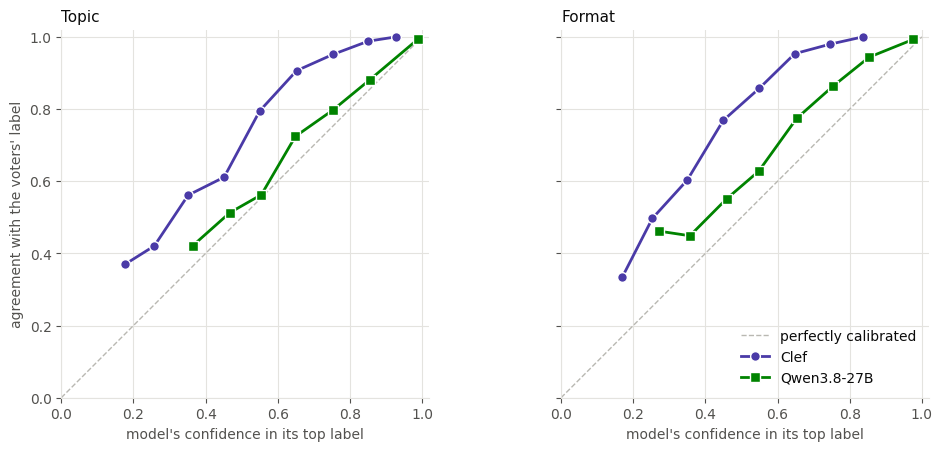

In [25]:
if reliability:
    fig, axes = plt.subplots(1, len(LABEL_TYPES), figsize=(10, 4.4), sharex=True, sharey=True, constrained_layout=True)
    markers = dict(zip(CANDIDATE_PAIR, ["o", "s"]))
    for ax, label_type in zip(np.atleast_1d(axes), LABEL_TYPES):
        ax.plot([0, 1], [0, 1], color="#b9b8b2", linewidth=1, linestyle="--", label="perfectly calibrated")
        for model in CANDIDATE_PAIR:
            bins = [b for b in reliability.get((label_type, model), []) if b["count"] >= 20]   # skip nearly empty bins
            ax.plot([b["mean_confidence"] for b in bins], [b["accuracy"] for b in bins], marker=markers[model], markersize=7,
                    linewidth=2, color=PAIR_COLORS[model], markeredgecolor="white", markeredgewidth=1, label=model)
        ax.set_title(f"{label_type.capitalize()}", loc="left")
        ax.set_xlabel("model's confidence in its top label")
        ax.set_xlim(0, 1.02)
        ax.set_ylim(0, 1.02)
        ax.set_aspect("equal")
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
    np.atleast_1d(axes)[0].set_ylabel("agreement with the voters' label")
    np.atleast_1d(axes)[-1].legend(frameon=False, loc="lower right")
    plt.show()

### Against the human annotator and the OpenAI models

Section 4 lists both models' κ with the human annotator. Here:

- **Three-way breakdown** of the pages the human labelled, as in section 10: where the
  two models differ, whose label does the human share?
- **κ with each OpenAI model** on the 100 evaluation documents in all six languages.

In [26]:
def top_label_names(model: str, label_type: str, language: str) -> dict[str, str]:
    # Top labels as short names, from the full records.
    return {doc_id: label_names[label_type][index] for doc_id, index in top.get((model, label_type, language), {}).items()}


three_way = []
for label_type in LABEL_TYPES if REFERENCE_ANNOTATOR in annotators else ():
    groups = Counter()
    for language in human_languages:
        human = annotations.get((REFERENCE_ANNOTATOR, label_type, language), {})
        first_labels, second_labels = top_label_names(candidate, label_type, language), top_label_names(chosen, label_type, language)
        for doc_id, human_label in human.items():
            first_match, second_match = first_labels[doc_id] == human_label, second_labels[doc_id] == human_label
            if first_match and second_match:
                groups["all three agree"] += 1
            elif first_match:
                groups[f"only {candidate} matches the human"] += 1
            elif second_match:
                groups[f"only {chosen} matches the human"] += 1
            elif first_labels[doc_id] == second_labels[doc_id]:
                groups["models agree, human differs"] += 1
            else:
                groups["all three differ"] += 1
    order = ["all three agree", f"only {candidate} matches the human", f"only {chosen} matches the human",
             "models agree, human differs", "all three differ"]
    three_way.append({"label type": label_type, "pages": sum(groups.values()), **{name: groups[name] for name in order}})
if three_way:
    display(pd.DataFrame(three_way))

api_rows = []
for label_type in LABEL_TYPES:
    for api_model in API_MODELS:
        row = {"label type": label_type, "OpenAI model": api_model}
        for model in CANDIDATE_PAIR:
            pairs = []
            for language in LANGUAGES:
                api_labels, model_labels = annotations.get((api_model, label_type, language), {}), top_label_names(model, label_type, language)
                pairs += [(api_labels[d], model_labels[d]) for d in sorted(api_labels.keys() & model_labels.keys())]
            if pairs:
                scores = agreement_scores(confusion_matrix(pairs, label_type))
                row["items"] = len(pairs)
                row[f"kappa: {model}"] = round(scores["kappa"], 3)
                row[f"agreement: {model}"] = round(scores["agreement"], 3)
        api_rows.append(row)
candidate_api = pd.DataFrame(api_rows)
display(candidate_api)

,label type,pages,all three agree,only Clef matches the human,only Qwen3.8-27B matches the human,"models agree, human differs",all three differ
0,topic,50,34,1,4,8,3
1,format,50,22,1,6,12,9


,label type,OpenAI model,items,kappa: Clef,agreement: Clef,kappa: Qwen3.8-27B,agreement: Qwen3.8-27B
0,topic,GPT-6 Luna,600,0.803,0.818,0.870,0.880
1,topic,GPT-6.1 Sol,600,0.809,0.823,0.841,0.853
2,format,GPT-6 Luna,600,0.608,0.632,0.678,0.697
3,format,GPT-6.1 Sol,600,0.585,0.608,0.682,0.700


### Where their labels differ

Pooled over languages: the labels whose counts differ most between the two models, and
the most frequent "chosen model's label → candidate's label" pairs. Large usage gaps
are different readings of a label definition, not noise.

In [27]:
candidate_confusions = {}
for label_type in LABEL_TYPES:
    pairs = []
    for language in LANGUAGES:
        documents = shared_documents(CANDIDATE_PAIR, label_type, language)
        pairs += [(top[(chosen, label_type, language)][d], top[(candidate, label_type, language)][d]) for d in documents]
    if not pairs:
        continue
    names = label_names[label_type]
    chosen_counts, candidate_counts = Counter(a for a, _ in pairs), Counter(b for _, b in pairs)
    gaps = pd.DataFrame({candidate: [candidate_counts[i] for i in range(len(names))],
                         chosen: [chosen_counts[i] for i in range(len(names))]}, index=names)
    gaps["difference"] = gaps[candidate] - gaps[chosen]
    counts = Counter((a, b) for a, b in pairs if a != b)
    candidate_confusions[label_type] = pd.DataFrame(
        [{chosen: names[a], candidate: names[b], "items": n} for (a, b), n in counts.most_common()])
    print(f"{label_type}: {sum(counts.values())} disagreements in {len(pairs)} items; largest differences in label usage:")
    display(gaps.reindex(gaps["difference"].abs().sort_values(ascending=False).index).head(8))
    print("most frequent disagreements:")
    display(candidate_confusions[label_type].head(8))

topic: 2281 disagreements in 12000 items; largest differences in label usage:


,Clef,Qwen3.8-27B,difference
Finance & Business,362,786,-424
Science & Tech.,1572,1293,279
Software,718,443,275
Home & Hobbies,304,552,-248
History,337,584,-247
Entertainment,617,791,-174
Literature,653,517,136
Health,1420,1325,95


most frequent disagreements:


,Qwen3.8-27B,Clef,items
0,Finance & Business,Software,148
1,Home & Hobbies,Science & Tech.,73
2,Entertainment,Literature,71
3,History,Travel,71
4,Education & Jobs,Science & Tech.,68
5,Finance & Business,Education & Jobs,67
6,Industrial,Science & Tech.,66
7,Finance & Business,Industrial,41


format: 3766 disagreements in 12000 items; largest differences in label usage:


,Clef,Qwen3.8-27B,difference
Bad example,398,978,-580
Knowledge Article,1795,1269,526
Truncated,152,593,-441
Content Listing,295,612,-317
Product Page,850,1145,-295
Q&A Forum,711,421,290
Spam / Ads,727,452,275
News Article,814,605,209


most frequent disagreements:


,Qwen3.8-27B,Clef,items
0,Truncated,Knowledge Article,164
1,Comment Section,Q&A Forum,144
2,Nonfiction Writing,News Article,110
3,Personal Blog,Nonfiction Writing,105
4,Bad example,Knowledge Article,94
5,Personal Blog,Comment Section,81
6,Product Page,Spam / Ads,71
7,Product Page,About (Org.),67


### Consistency across languages

A translated page should get the same label as its English original. Per model, label
type and language:

- **same label as English:** share of documents whose top label matches the English one.
- **JSD to English:** mean divergence between the translated and the English
  distribution. Flat distributions get low values almost automatically, so this is not
  comparable between a confident and an unconfident model.
- **normalized consistency:** 1 − JSD(translation, English) / JSD(translation, English
  version of a *random other* document). 1 means translations get the same
  distribution, 0 means no more similar than unrelated documents. This corrects for how
  flat a model's distributions are.

Remember the caveat from the top of this section: a model that shows the labels in the
same order in every language (Clef) gets some consistency for free, because any
position preference pushes all languages the same way. The chat models were given a
different label order per language to prevent exactly that.

In [28]:
consistency_pair_rows = []
for label_type in LABEL_TYPES:
    for model in CANDIDATE_PAIR:
        for language in LANGUAGES[1:]:
            documents = shared_documents([model], label_type, language)
            documents = [d for d in documents if d in full.get((model, label_type, LANGUAGES[0]), {})]
            if len(documents) < 2:
                continue
            translated = [full[(model, label_type, language)][d].logprobs for d in documents]
            english = [full[(model, label_type, LANGUAGES[0])][d].logprobs for d in documents]
            parallel = statistics.fmean(jensen_shannon_bits(a, b) for a, b in zip(translated, english))
            unrelated = random_pair_jsd_bits(translated, english, SEED)
            consistency_pair_rows.append({
                "label type": label_type, "model": model, "language": language, "documents": len(documents),
                "same label as English": np.mean([top[(model, label_type, language)][d] == top[(model, label_type, LANGUAGES[0])][d]
                                                  for d in documents]),
                "JSD to English (bits)": parallel, "normalized consistency": 1 - parallel / unrelated,
            })
candidate_consistency = pd.DataFrame(consistency_pair_rows)
for measure in ("same label as English", "normalized consistency"):
    print(measure)
    display(candidate_consistency.pivot(index=["label type", "model"], columns="language", values=measure)
            .assign(mean=lambda t: t.mean(axis=1)).round(3))

same label as English


language                finnish  german  hungarian  icelandic  ukrainian   mean
label type model                                                               
format     Clef           0.796   0.839      0.809      0.794      0.813  0.810
           Qwen3.8-27B    0.796   0.806      0.789      0.774      0.806  0.794
topic      Clef           0.912   0.926      0.913      0.908      0.922  0.916
           Qwen3.8-27B    0.902   0.912      0.910      0.890      0.915  0.906

normalized consistency


language                finnish  german  hungarian  icelandic  ukrainian   mean
label type model                                                               
format     Clef           0.938   0.960      0.941      0.937      0.947  0.944
           Qwen3.8-27B    0.894   0.913      0.893      0.882      0.904  0.897
topic      Clef           0.977   0.986      0.980      0.973      0.981  0.979
           Qwen3.8-27B    0.958   0.968      0.960      0.950      0.961  0.959

### Speed

Throughput is read from the job logs (`LOGS_DIR/distribution_*.err`) of the runs on the
parallel dataset: every "Processed N total tokens in S seconds" line and the number of
documents scored. To compare like with like:

- chat-model runs count only with the rotated prompt order, the setting of the final
  runs (earlier runs used another order, and some of them two GPUs);
- per label type, only the languages for which *both* models have such a log are used
  (translations are longer than the English pages, so the language mix matters); the
  `languages` column shows which.

**Tokens per second is not comparable between the two models**, because their inputs
differ in length: the chat prompt repeats the label list and carries five examples
(most of it reused from vLLM's cache), while Clef's input is the page plus one copy of
the instructions and labels. **Documents per second** and the cost per 1,000 documents
are the comparable figures. Model loading is not included.

In [29]:
def scoring_throughput(path: Path) -> dict | None:
    # Return the run settings and summed scoring throughput of one job log, or None if it scored nothing.
    text = path.read_text(encoding="utf-8", errors="replace")
    def setting(name: str) -> str | None:
        match = re.search(rf"\]\s+{name}: (\S+)", text)
        return match.group(1) if match else None
    chunks = re.findall(r"Processed (\d+) total tokens in ([\d.]+) seconds", text)
    documents = sum(int(n) for n in re.findall(r"Processed (\d+) documents in batch", text))
    if not chunks or not documents:
        return None
    return {"model_name": setting("model_name"), "label_type": setting("label_type"), "dataset": setting("input_dataset"),
            "language": (setting("language") or "").lower(), "prompt_order": setting("prompt_order"),
            # Only the decision-model script logs this setting; its label order is fixed.
            "decision_model": setting("max_batch_tokens") is not None,
            "gpus": int(setting("tensor_parallel_size") or 1),
            "tokens": sum(int(tokens) for tokens, _ in chunks), "seconds": sum(float(seconds) for _, seconds in chunks),
            "documents": documents}


runs_by_model = {model: [] for model in CANDIDATE_PAIR}
for path in sorted(LOGS_DIR.glob("distribution_*.err")):
    run = scoring_throughput(path)
    if run is None or run["dataset"] != "MultiSynt/MT-Nemotron-CC":
        continue
    for model in CANDIDATE_PAIR:
        is_model = (run["model_name"] or "").split("/")[-1].lower() == OPEN_MODELS[model].lower()
        # A chat-model log without a prompt order is from before the rotated order existed.
        if is_model and (run["decision_model"] or run["prompt_order"] == "rotated"):
            runs_by_model[model].append(run)

speed_rows = []
for label_type in LABEL_TYPES:
    # Languages both models have a comparable log for.
    common = set.intersection(*({run["language"] for run in runs if run["label_type"] == label_type}
                                for runs in runs_by_model.values()))
    for model, runs in runs_by_model.items():
        selected = [run for run in runs if run["label_type"] == label_type and run["language"] in common]
        if not selected:
            continue
        tokens, seconds, documents = (sum(run[key] for run in selected) for key in ("tokens", "seconds", "documents"))
        gpu_seconds = sum(run["seconds"] * run["gpus"] for run in selected)
        speed_rows.append({
            "model": model, "label type": label_type, "languages": ", ".join(lang for lang in LANGUAGES if lang in common),
            "runs": len(selected), "GPUs": "/".join(sorted({str(run["gpus"]) for run in selected})), "documents": documents,
            "tokens per document": round(tokens / documents), "tokens per second": round(tokens / seconds),
            "documents per second": round(documents / seconds, 2),
            "BU per 1,000 documents (scoring only)": round(gpu_seconds / 3600 * BU_PER_GPU_HOUR / documents * 1000, 1),
        })
candidate_speed = pd.DataFrame(speed_rows).sort_values(["label type", "model"], ascending=[False, True]) if speed_rows else pd.DataFrame()
if speed_rows:
    display(candidate_speed.reset_index(drop=True))
else:
    print(f"No job logs of {CANDIDATE_PAIR} found in {LOGS_DIR}")

,model,label type,languages,runs,GPUs,documents,tokens per document,tokens per second,documents per second,"BU per 1,000 documents (scoring only)"
0,Clef,topic,"english, ukrainian",3,1,4000,1979,4461,2.25,24.6
1,Qwen3.8-27B,topic,"english, ukrainian",2,1,4000,4465,11685,2.62,21.2
2,Clef,format,"english, finnish, german, hungarian, icelandic, ukrainian",6,1,12000,2467,4518,1.83,30.3
3,Qwen3.8-27B,format,"english, finnish, german, hungarian, icelandic, ukrainian",6,1,12000,5604,11582,2.07,26.9


## 12. Summary

The headline numbers in one place, computed from the tables above so they stay correct
when the data or parameters change: the focus pair, every model's agreement with the
human annotator, the open model against the OpenAI model (section 10), and the
candidate against the chosen open model (section 11).

In [30]:
consistency = pd.DataFrame(consistency_rows, columns=["annotator", "label type", "same label in all languages"]
                           if not consistency_rows else None).set_index(["annotator", "label type"])
for label_type in LABEL_TYPES:
    row = overall[(overall["pair"] == f"{first} vs {second}") & (overall["label type"] == label_type)].iloc[0]
    part = by_language[by_language["label type"] == label_type].set_index("language")["kappa"]
    top = confusions[label_type].iloc[0]
    print(f"{label_type.upper()}: {first} vs {second}, {row['items']} items from {row['documents']} documents")
    print(f"  agreement {row['agreement']:.3f} ({row['agreement 95% CI']}), Cohen's kappa {row['kappa']:.3f} ({row['kappa 95% CI']})")
    print(f"  macro F1 {row['macro F1']:.3f} ({row['macro F1 95% CI']}), weighted F1 {row['weighted F1']:.3f} ({row['weighted F1 95% CI']})")
    print(f"  kappa per language: highest {part.idxmax()} {part.max():.3f}, lowest {part.idxmin()} {part.min():.3f}")
    print(f"  most frequent disagreement: {top[first]} -> {top[second]} ({top['items']} items)")
    for annotator in (first, second):
        if (annotator, label_type) in consistency.index:
            share = consistency.loc[(annotator, label_type), "same label in all languages"]
            print(f"  {annotator}: same label in all languages for {share:.0%} of documents")
    if human_rows:
        part = human_agreement[human_agreement["label type"] == label_type].sort_values("kappa", ascending=False)
        print(f"  agreement with {REFERENCE_ANNOTATOR} on {int(part['items'].iloc[0])} items (Cohen's kappa, 95% interval):")
        for _, model_row in part.iterrows():
            print(f"    {model_row['model']:<26} {model_row['kappa']:.3f} ({model_row['kappa 95% CI']}), agreement {model_row['agreement']:.3f}")
    pair = open_pairs[(open_pairs["label type"] == label_type) & (open_pairs["pair"] == f"{open_model} vs {api_model}")].iloc[0]
    soft = open_probabilities[open_probabilities["label type"] == label_type].iloc[0]
    print(f"  {open_model} vs {api_model} on {pair['items']} items: agreement {pair['agreement']:.3f}, "
          f"Cohen's kappa {pair['kappa']:.3f} ({pair['kappa 95% CI']}), macro F1 {pair['macro F1']:.3f}; "
          f"{api_model}'s label within {open_model}'s top 2 for {soft['within top 2']:.0%} of items")
    pooled = candidate_agreement[(candidate_agreement["label type"] == label_type) & (candidate_agreement["language"] == "all")]
    if len(pooled):
        print(f"  {candidate} vs {chosen} on {int(pooled['documents'].iloc[0])} items: agreement {pooled['agreement'].iloc[0]:.3f}, "
              f"Cohen's kappa {pooled['kappa'].iloc[0]:.3f}")
        for model in CANDIDATE_PAIR:
            line = f"    {model:<14}"
            consensus = candidate_consensus[(candidate_consensus["label type"] == label_type) & (candidate_consensus["model"] == model)]
            if len(consensus):
                line += (f" agreement with {' + '.join(CONSENSUS_VOTERS)} {consensus['agreement'].iloc[0]:.3f}, "
                         f"log loss {consensus['log loss (bits)'].iloc[0]:.2f} bits, calibration error {consensus['calibration error'].iloc[0]:.3f};")
            consistent = candidate_consistency[(candidate_consistency["label type"] == label_type) & (candidate_consistency["model"] == model)]
            if len(consistent):
                line += f" same label as English {consistent['same label as English'].mean():.3f};"
            speed = candidate_speed[(candidate_speed["label type"] == label_type) & (candidate_speed["model"] == model)] if speed_rows else []
            if len(speed):
                line += f" {speed['documents per second'].iloc[0]} documents/s"
            print(line.rstrip(";"))
    print()

TOPIC: GPT-6 Luna vs GPT-6.1 Sol, 600 items from 100 documents
  agreement 0.867 (0.810–0.917), Cohen's kappa 0.856 (0.794–0.909)
  macro F1 0.824 (0.699–0.862), weighted F1 0.869 (0.814–0.921)
  kappa per language: highest english 0.881, lowest icelandic 0.816
  most frequent disagreement: Entertainment -> Art & Design (8 items)
  GPT-6 Luna: same label in all languages for 79% of documents
  GPT-6.1 Sol: same label in all languages for 90% of documents
  agreement with Human on 50 items (Cohen's kappa, 95% interval):
    Qwen3.8-27B                0.738 (0.598–0.846), agreement 0.760
    GPT-6.1 Sol                0.717 (0.574–0.842), agreement 0.740
    Clef                       0.673 (0.535–0.799), agreement 0.700
    Qwen3.5-122B-A10B          0.672 (0.525–0.800), agreement 0.700
    Mistral-Medium-3.5-128B    0.652 (0.504–0.778), agreement 0.680
    GPT-6 Luna                 0.650 (0.498–0.776), agreement 0.680
    Gemma-4-31B                0.629 (0.475–0.757), agreement 0.660